In [3]:
from __future__ import annotations

import gc
import hashlib
import importlib.metadata
import itertools
import json
import logging
import math
import os
import platform
import random
import sys
import time
import zipfile
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import sparse, stats
from scipy.sparse.csgraph import connected_components
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    adjusted_rand_score, average_precision_score, roc_auc_score,
    roc_curve, precision_recall_curve,
)
from sklearn.model_selection import (
    StratifiedGroupKFold, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Configuration

In [4]:
CONFIG = {
    "random_state": 42,
    "cyber_full_path": None,
    "cyber_filename": "ton_iot.csv",
    "cyber_subdir": "Datasets/TON_IoT",
    "cyber_target_col": "label",
    "cyber_context_col": "type",
    "cyber_subset_provenance": "Parent-dataset subset selection not supplied; input file retained without resampling.",
    "strict_identifier_exclusion": True,
    "video_n_cameras": 10,
    "video_n_zones": 5,
    "video_days": 60,
    "video_event_freq": "2min",
    "video_hidden_incident_rate": 0.18,
    "video_correlated_burst_prob": 0.08,
    "video_label_flip_prob": 0.04,
    "force_regenerate_video_dataset": True,
    "train_frac": 0.60,
    "val_frac": 0.10,
    "test_frac": 0.30,
    "n_repetitions": 20,
    "n_holdout_repetitions": 10,
    "n_bootstrap": 2000,
    "alpha": 0.05,
    "bootstrap_block_events": 50,
    "bootstrap_block_grid": [25, 50, 100],
    "fusion_bootstrap_block_seconds": 6000,
    "models_to_run": ["LogisticRegression", "CalibratedLogisticRegression", "RandomForest", "ExtraTrees"],
    "video_models": ["LogisticRegression", "RandomForest", "ExtraTrees"],
    "n_estimators": 200,
    "max_depth": 12,
    "min_samples_leaf": 8,
    "class_weight": "balanced_subsample",
    "logistic_max_iter": 2000,
    "calibration_folds": 3,
    "n_jobs": -1,
    "fusion_window_seconds": 120,
    "window_grid": [30, 60, 120, 300, 600],
    "fusion_confidence_cap": 0.80,
    "fusion_uncertainty_penalty": 0.30,
    "window_uncertainty_threshold": 0.45,
    "threshold_grid": np.r_[np.linspace(0.0, 1.0, 101), np.nextafter(1.0, 2.0)].tolist(),
    "surrogate_cyber_spacing_seconds": 20,
    "window_origin": "2024-01-01 00:00:00",
    "ordering_schemes": ["native", "random", "score_interleaved"],
    "n_random_orderings": 10,
    "offset_seconds_grid": [-300, -120, 0, 120, 300],
    "missing_fraction_grid": [0.0, 0.1, 0.3, 0.5],
    "paired_diagnostic_repetitions": 10,
    "graph_similarity_metric": "cosine",
    "graph_similarity_threshold": 0.92,
    "graph_similarity_eps_grid": [0.92, 0.96, 0.98, 0.995, 0.999],
    "graph_max_similarity_sample": 5000,
    "graph_sample_grid": [1000, 2500, 5000],
    "graph_temporal_edge_seconds": 60,
    "graph_temporal_grid": [0, 30, 60, 120],
    "graph_similarity_time_limit_seconds": None,
    "graph_similarity_time_grid": [None, 120, 600, 3600],
    "graph_similarity_sampling": "seeded_uniform",
    "graph_hub_policy": "alert_windows",
    "graph_similarity_chunk_size": 256,
    "graph_store_edges": True,
    "min_campaign_evidence_nodes": 2,
    "campaign_alpha": 1.0,
    "campaign_beta": 0.10,
    "campaign_gamma": 0.50,
    "campaign_beta_grid": [0.0, 0.05, 0.10, 0.20],
    "campaign_gamma_grid": [0.0, 0.25, 0.50, 1.0],
    "permutation_repeats": 10,
    "permutation_max_rows": 3000,
    "save_models": True,
    "archive_previous_run": True,
    "show_figures": True,
}

In [5]:
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = Path(os.environ.get("CHBR_PROJECT_ROOT", "/content/drive/MyDrive" if IN_COLAB else str(Path.cwd()))).resolve()
RUN_DIR = ROOT / "Outputs" / "CHBR_R1_v3"
ARCHIVE_DIR = None
if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
    if not CONFIG["archive_previous_run"]:
        raise FileExistsError(f"Output directory is not empty: {RUN_DIR}. Enable archive_previous_run or archive it manually.")
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    ARCHIVE_DIR = RUN_DIR.with_name(f"{RUN_DIR.name}_archive_{stamp}")
    RUN_DIR.rename(ARCHIVE_DIR)
FIG_PATH = RUN_DIR / "figures"
TABLE_PATH = RUN_DIR / "tables"
LATEX_PATH = RUN_DIR / "latex"
PRED_PATH = TABLE_PATH / "predictions"
MODEL_PATH = RUN_DIR / "models"
for directory in (RUN_DIR, FIG_PATH, TABLE_PATH, LATEX_PATH, PRED_PATH, MODEL_PATH):
    directory.mkdir(parents=True, exist_ok=True)

LOGGER = logging.getLogger("physical_cyber_fusion")
for handler in list(LOGGER.handlers):
    handler.close()
    LOGGER.removeHandler(handler)
LOGGER.setLevel(logging.INFO)
LOGGER.propagate = False
for handler in (logging.StreamHandler(sys.stdout), logging.FileHandler(RUN_DIR / "run_log.txt", encoding="utf-8")):
    handler.setFormatter(logging.Formatter("%(message)s"))
    LOGGER.addHandler(handler)
log = LOGGER.info
ARTIFACTS = {}
EXPERIMENT_STATUS = []
START_TIME = time.perf_counter()
random.seed(CONFIG["random_state"])
np.random.seed(CONFIG["random_state"])


def json_value(obj):
    if isinstance(obj, dict):
        return {str(k): json_value(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, np.ndarray)):
        return [json_value(x) for x in obj]
    if isinstance(obj, (np.integer, np.bool_)):
        return obj.item()
    if isinstance(obj, (float, np.floating)):
        return float(obj) if np.isfinite(obj) else None
    if isinstance(obj, (Path, pd.Timestamp)):
        return str(obj)
    return obj


def register(path, description=""):
    ARTIFACTS[str(Path(path).relative_to(RUN_DIR))] = description
    return Path(path)


def save_json(obj, name, directory=TABLE_PATH):
    path = directory / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(json_value(obj), indent=2, allow_nan=False), encoding="utf-8")
    return register(path)


def save_csv(frame, name, directory=TABLE_PATH):
    path = directory / name
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False, float_format="%.17g")
    return register(path)


def table(frame, csv_name, tex_name=None, caption="", label=None, latex_frame=None):
    save_csv(frame, csv_name)
    if tex_name:
        presentation = frame if latex_frame is None else latex_frame
        column_format = None
        if "generating_expression" in presentation:
            presentation = presentation.copy()
            presentation["generating_expression"] = presentation.generating_expression.str.replace("+", " + ", regex=False).str.replace(",", ", ", regex=False)
            column_format = r"p{0.19\textwidth}p{0.21\textwidth}p{0.50\textwidth}"
        body = presentation.to_latex(index=False, escape=True, float_format=lambda x: f"{x:.5g}", na_rep="--", column_format=column_format)
        text = ("\\begin{table*}[t]\n\\centering\n\\small\n"
                f"\\caption{{{caption}}}\n\\label{{{label or 'tab:' + Path(tex_name).stem}}}\n"
                + "\\resizebox{\\textwidth}{!}{%\n" + body + "}\n\\end{table*}\n")
        path = LATEX_PATH / tex_name
        path.write_text(text, encoding="utf-8")
        register(path)
    return frame


def save_fig(name, fig=None):
    fig = fig or plt.gcf()
    path = FIG_PATH / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    register(path)
    svg = path.with_suffix(".svg")
    fig.savefig(svg, bbox_inches="tight")
    register(svg)
    if CONFIG["show_figures"]:
        display(fig)
    plt.close(fig)


def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def status(stage, state, detail=""):
    EXPERIMENT_STATUS.append({"stage": stage, "status": state, "detail": detail})
    save_csv(pd.DataFrame(EXPERIMENT_STATUS), "experiment_status.csv")
    log(f"{stage}: {state}. {detail}")


assert np.isclose(CONFIG["train_frac"] + CONFIG["val_frac"] + CONFIG["test_frac"], 1.0)
assert 0 < CONFIG["fusion_confidence_cap"] <= 1
assert 0 <= CONFIG["fusion_uncertainty_penalty"] <= 1
assert CONFIG["graph_similarity_metric"] == "cosine"
assert CONFIG["graph_hub_policy"] in ("alert_windows", "occupied_windows")
assert CONFIG["graph_similarity_sampling"] == "seeded_uniform"
assert 0 < CONFIG["alpha"] < 1
assert all(CONFIG[k] > 0 for k in ("n_repetitions", "n_holdout_repetitions", "n_bootstrap",
    "paired_diagnostic_repetitions", "n_random_orderings", "bootstrap_block_events", "fusion_bootstrap_block_seconds"))
assert all(np.isclose(CONFIG[k] * 10, round(CONFIG[k] * 10)) for k in ("train_frac", "val_frac", "test_frac"))
assert all(CONFIG[k] > 0 for k in ("train_frac", "val_frac", "test_frac"))
assert "RandomForest" in CONFIG["models_to_run"]
assert "CalibratedLogisticRegression" not in CONFIG["video_models"], "The calibrated comparator is defined for cyber predictor groups."
assert CONFIG["graph_similarity_chunk_size"] > 0 and CONFIG["graph_max_similarity_sample"] >= 0
assert 0 <= CONFIG["graph_similarity_threshold"] <= 1
assert CONFIG["graph_temporal_edge_seconds"] >= 0
assert all(0 <= value < 1 for value in CONFIG["missing_fraction_grid"])

log(f"Project root: {ROOT}")
log(f"Output directory: {RUN_DIR}")
if ARCHIVE_DIR:
    log(f"Previous outputs archived at: {ARCHIVE_DIR}")
save_json(CONFIG, "config.json")
ENVIRONMENT = {p: importlib.metadata.version(p) for p in (
    "numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "joblib", "nbformat", "nbclient"
)}
save_json({"python": sys.version, "platform": platform.platform(), "packages": ENVIRONMENT}, "environment.json")

Project root: F:\MBZUAI UAE\7-Elsevier-CHBR-Human-centered\GitHub-v2
Output directory: F:\MBZUAI UAE\7-Elsevier-CHBR-Human-centered\GitHub-v2\Outputs\CHBR_R1_v3


WindowsPath('F:/MBZUAI UAE/7-Elsevier-CHBR-Human-centered/GitHub-v2/Outputs/CHBR_R1_v3/tables/environment.json')

## Metrics and resampling

Intervals are percentile bootstrap intervals conditional on the fitted models and frozen thresholds. Surveillance observations use circular time blocks; cyber observations use predictor-pattern clusters. Repeated-fit standard deviations are reported separately. Exact binomial reference limits for recall and FPR additionally assume IID trials and do not replace dependence-aware intervals. Average precision is stored as `pr_auc`; undefined metrics remain missing.

In [6]:
METRIC_KEYS = ["accuracy", "bal_acc", "precision", "recall", "f1", "roc_auc", "pr_auc", "fpr",
               "precision_benign", "recall_benign", "f1_benign", "brier", "log_loss", "ece"]


def divide(a, b):
    return float(a / b) if b > 0 else np.nan


def uncertainty_proxy(probability):
    p = np.asarray(probability, dtype=float)
    if np.any(np.isfinite(p) & ((p < 0) | (p > 1))):
        raise ValueError("Probability outside [0, 1].")
    return 1.0 - 2.0 * np.abs(p - 0.5)


class MetricEvaluator:
    """Weighted binary metrics with fixed score ordering for bootstrap evaluation."""

    def __init__(self, y, score, threshold=0.5, n_bins=15):
        labels = np.asarray(y)
        if not np.isin(labels, [0, 1]).all():
            raise ValueError("Labels must be binary before type conversion.")
        self.y = labels.astype(np.int8)
        self.score = np.asarray(score, dtype=float)
        if len(self.y) != len(self.score) or not np.isin(self.y, [0, 1]).all():
            raise ValueError("Invalid binary evaluation arrays.")
        if not np.isfinite(self.score).all() or ((self.score < 0) | (self.score > 1)).any():
            raise ValueError("Scores must be finite and lie in [0, 1].")
        self.pred = self.score >= threshold
        self.order = np.argsort(self.score, kind="stable")
        self.starts = np.r_[0, np.flatnonzero(np.diff(self.score[self.order])) + 1] if len(self.y) else np.array([], int)
        self.bins = np.minimum((self.score * n_bins).astype(int), n_bins - 1)
        self.n_bins = n_bins
        q = np.clip(self.score, 1e-15, 1 - 1e-15)
        self.loss = -(self.y * np.log(q) + (1 - self.y) * np.log1p(-q))
        self.squared_error = (self.y - self.score) ** 2
        self.masks = [((self.y == a) & (self.pred == b)) for a, b in ((0, 0), (0, 1), (1, 0), (1, 1))]

    def __call__(self, weight=None):
        w = np.ones(len(self.y)) if weight is None else np.asarray(weight, float)
        if len(w) != len(self.y) or not np.isfinite(w).all() or (w < 0).any():
            raise ValueError("Invalid evaluation weights.")
        total = w.sum()
        tn, fp, fn, tp = [float(w[m].sum()) for m in self.masks]
        positive, negative = tp + fn, tn + fp
        recall, specificity = divide(tp, positive), divide(tn, negative)
        out = dict(n=int(len(self.y)), n_positive=int(self.y.sum()), tn=tn, fp=fp, fn=fn, tp=tp,
                   accuracy=divide(tp + tn, total),
                   bal_acc=(recall + specificity) / 2 if positive and negative else np.nan,
                   precision=divide(tp, tp + fp), recall=recall,
                   f1=divide(2 * tp, 2 * tp + fp + fn), fpr=divide(fp, negative),
                   precision_benign=divide(tn, tn + fn), recall_benign=specificity,
                   f1_benign=divide(2 * tn, 2 * tn + fp + fn), roc_auc=np.nan, pr_auc=np.nan,
                   brier=divide(np.dot(w, self.squared_error), total),
                   log_loss=divide(np.dot(w, self.loss), total), ece=np.nan)
        if total:
            count = np.bincount(self.bins, weights=w, minlength=self.n_bins)
            yp = np.bincount(self.bins, weights=w * self.y, minlength=self.n_bins)
            pp = np.bincount(self.bins, weights=w * self.score, minlength=self.n_bins)
            out["ece"] = float(np.abs(yp - pp).sum() / total)
        if positive and negative:
            sy = self.y[self.order]
            sw = w[self.order]
            pos = np.add.reduceat(sw * sy, self.starts)
            neg = np.add.reduceat(sw * (1 - sy), self.starts)
            out["roc_auc"] = float(np.dot(pos, np.cumsum(neg) - 0.5 * neg) / (positive * negative))
            pdesc, ndesc = pos[::-1], neg[::-1]
            cp, ca = np.cumsum(pdesc), np.cumsum(pdesc + ndesc)
            precision = np.divide(cp, ca, out=np.zeros_like(cp), where=ca > 0)
            out["pr_auc"] = float(np.dot(precision, pdesc) / positive)
        return out


def metrics(y, score, threshold=0.5):
    y, score = np.asarray(y), np.asarray(score, float)
    keep = np.isfinite(score)
    out = MetricEvaluator(y[keep], score[keep], threshold)()
    out.update(n_total=len(y), n_scored=int(keep.sum()), coverage=float(keep.mean()) if len(y) else np.nan,
               abstained_positive=int(np.sum(y[~keep] == 1)), abstained_negative=int(np.sum(y[~keep] == 0)))
    return out


def select_threshold(y, score):
    y, score = np.asarray(y), np.asarray(score, float)
    keep = np.isfinite(score)
    y, score = y[keep], score[keep]
    if len(np.unique(y)) != 2:
        return 0.5, "fixed_0.5_single_class_or_empty_validation"
    pos, neg = score[y == 1], score[y == 0]
    candidates = []
    for threshold in CONFIG["threshold_grid"]:
        sensitivity = np.mean(pos >= threshold)
        fpr = np.mean(neg >= threshold)
        candidates.append(((sensitivity + 1 - fpr) / 2, -fpr, -abs(threshold - 0.5), threshold))
    return float(max(candidates)[-1]), "validation_bal_acc_then_fpr_then_distance_to_0.5"

In [7]:
@dataclass
class ResamplingPlan:
    n: int
    mode: str
    block: int = 50
    groups: object = None
    seed: int = 42

    def draws(self, repetitions):
        rng = np.random.default_rng(self.seed)
        if self.mode == "cluster":
            _, inverse = np.unique(np.asarray(self.groups), return_inverse=True)
            count = int(inverse.max()) + 1
            for _ in range(repetitions):
                sample = rng.integers(0, count, count)
                yield np.bincount(sample, minlength=count)[inverse].astype(float)
        elif self.mode == "block":
            length = max(1, min(self.block, self.n))
            for _ in range(repetitions):
                starts = rng.integers(0, self.n, math.ceil(self.n / length))
                indices = ((starts[:, None] + np.arange(length)) % self.n).ravel()[:self.n]
                yield np.bincount(indices, minlength=self.n).astype(float)
        else:
            raise ValueError(self.mode)

    def permutation_groups(self):
        return np.asarray(self.groups) if self.mode == "cluster" else np.arange(self.n) // max(1, self.block)


def binomial_reference_interval(successes, trials):
    if trials <= 0:
        return np.nan, np.nan
    alpha = CONFIG["alpha"]
    lower = stats.beta.ppf(alpha / 2, successes, trials - successes + 1) if successes > 0 else 0.0
    upper = stats.beta.ppf(1 - alpha / 2, successes + 1, trials - successes) if successes < trials else 1.0
    return float(lower), float(upper)


def infer_family(y, score_map, thresholds, plan, comparisons=(), n_boot=None):
    """All models share evaluation rows and bootstrap draws; thresholds stay fixed."""
    y = np.asarray(y)
    evaluators = {name: MetricEvaluator(y, score, thresholds[name]) for name, score in score_map.items()}
    point = {name: evaluator() for name, evaluator in evaluators.items()}
    B = int(CONFIG["n_bootstrap"] if n_boot is None else n_boot)
    samples = {name: np.full((B, len(METRIC_KEYS)), np.nan) for name in score_map}
    for b, weights in enumerate(plan.draws(B)):
        for name, evaluator in evaluators.items():
            result = evaluator(weights)
            samples[name][b] = [result[key] for key in METRIC_KEYS]
    rows = []
    for name in score_map:
        row = {"name": name, **point[name], "threshold": thresholds[name], "ci_method": plan.mode + "_percentile",
               "bootstrap_repetitions": B, "resampling_block": plan.block if plan.mode == "block" else np.nan}
        for j, key in enumerate(METRIC_KEYS):
            valid = samples[name][:, j]
            valid = valid[np.isfinite(valid)]
            row[key + "_lo"], row[key + "_hi"] = np.quantile(valid, [CONFIG["alpha"] / 2, 1 - CONFIG["alpha"] / 2]) if len(valid) else (np.nan, np.nan)
            row[key + "_valid_bootstrap"] = len(valid)
        row["fpr_binomial_reference_lo"], row["fpr_binomial_reference_hi"] = binomial_reference_interval(point[name]["fp"], point[name]["tn"] + point[name]["fp"])
        row["recall_binomial_reference_lo"], row["recall_binomial_reference_hi"] = binomial_reference_interval(point[name]["tp"], point[name]["tp"] + point[name]["fn"])
        row["binomial_reference_assumption"] = "IID trials; not cluster- or time-adjusted"
        rows.append(row)
    differences = []
    for a, b in comparisons:
        for j, key in enumerate(METRIC_KEYS):
            draw = samples[a][:, j] - samples[b][:, j]
            valid = draw[np.isfinite(draw)]
            lo, hi = np.quantile(valid, [CONFIG["alpha"] / 2, 1 - CONFIG["alpha"] / 2]) if len(valid) else (np.nan, np.nan)
            differences.append({"comparison": f"{a} - {b}", "a": a, "b": b, "metric": key,
                                "mean_diff": point[a][key] - point[b][key], "ci_lo": lo, "ci_hi": hi,
                                "valid_bootstrap": len(valid), "p_value": np.nan, "p_holm": np.nan})
    dif = pd.DataFrame(differences)
    if len(dif):
        for a, b in comparisons:
            p = paired_balanced_accuracy_test(y, evaluators[a].pred, evaluators[b].pred, plan, B)
            dif.loc[(dif.a == a) & (dif.b == b) & (dif.metric == "bal_acc"), "p_value"] = p
        mask = dif.p_value.notna()
        dif.loc[mask, "p_holm"] = holm(dif.loc[mask, "p_value"].to_numpy())
    return pd.DataFrame(rows), dif, samples


def paired_balanced_accuracy_test(y, pred_a, pred_b, plan, repetitions):
    y = np.asarray(y)
    p, n = np.sum(y == 1), np.sum(y == 0)
    if not p or not n:
        return np.nan
    contribution = ((pred_a == y).astype(float) - (pred_b == y).astype(float)) * np.where(y == 1, 0.5 / p, 0.5 / n)
    _, groups = np.unique(plan.permutation_groups(), return_inverse=True)
    units = np.bincount(groups, weights=contribution)
    observed = abs(units.sum())
    rng = np.random.default_rng(plan.seed + 917)
    exceed = 0
    for _ in range(repetitions):
        statistic = abs(np.dot(rng.choice([-1, 1], len(units)), units))
        exceed += statistic >= observed - 1e-14
    return (exceed + 1) / (repetitions + 1)


def holm(pvalues):
    p = np.asarray(pvalues, float)
    order = np.argsort(p)
    corrected = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]))
    result = np.empty_like(p)
    result[order] = corrected
    return result


def repetition_summary(frame, groups):
    return frame.groupby(groups, dropna=False)[METRIC_KEYS].agg(["mean", "std", "min", "max", "count"]).pipe(
        lambda x: x.set_axis([f"{a}_{b}" for a, b in x.columns], axis=1).reset_index())


def interval_table(frame, identity):
    output = frame[identity].copy()
    for metric in ("bal_acc", "roc_auc", "pr_auc", "f1", "recall", "fpr"):
        output[metric] = [f"{p:.3f} [{lo:.3f}, {hi:.3f}]" if np.isfinite(p) and np.isfinite(lo) else "--"
                          for p, lo, hi in zip(frame[metric], frame[metric + "_lo"], frame[metric + "_hi"])]
    return output


def difference_table(frame, identity=("comparison",)):
    selected = frame[frame.metric == "bal_acc"]
    return selected[list(identity) + ["mean_diff", "ci_lo", "ci_hi", "p_value", "p_holm"]].copy()


def variability_table(frame, identity):
    return frame[list(identity) + [key + suffix for key in ("bal_acc", "roc_auc", "fpr") for suffix in ("_mean", "_std")]].copy()

## Data generation and provenance

The surveillance generator is fixed independently of the cyber input size. Its latent state and label-generating probability are excluded from predictive inputs. The cyber file is used as supplied after exact-row deduplication; no balancing or label-conditioned subset selection is applied.

In [8]:
def generate_realistic_video_events(config, rng):
    n_cameras, n_zones = int(config["video_n_cameras"]), int(config["video_n_zones"])
    start = pd.Timestamp("2024-01-01 00:00:00")
    frequency = pd.to_timedelta(config["video_event_freq"])
    ts = pd.date_range(start, start + pd.Timedelta(days=config["video_days"]) - frequency, freq=frequency)
    n = len(ts)
    camera_ids = rng.integers(0, n_cameras, n)
    zone_ids = rng.integers(0, n_zones, n)
    hidden = np.zeros(n, dtype=int)
    base = float(config["video_hidden_incident_rate"])
    burst = float(config["video_correlated_burst_prob"])
    for i in range(n):
        p = base if i == 0 else min(max(base + (burst if hidden[i - 1] == 1 else 0.0), 0.0), 0.95)
        hidden[i] = rng.binomial(1, p)
    camera_risk = rng.normal(0, 0.35, n_cameras)
    zone_risk = rng.normal(0, 0.40, n_zones)
    motion = np.clip(0.35 + 0.35 * hidden + camera_risk[camera_ids] * 0.15 + rng.normal(0, 0.18, n), 0, 1)
    density = np.clip(0.30 + 0.30 * hidden + zone_risk[zone_ids] * 0.20 + rng.normal(0, 0.20, n), 0, 1)
    authenticity = np.clip(0.65 - 0.15 * hidden + rng.normal(0, 0.20, n), 0, 1)
    consistency = np.clip(0.60 - 0.10 * hidden + rng.normal(0, 0.22, n), 0, 1)
    uncertainty = np.clip(0.35 + 0.20 * hidden + rng.normal(0, 0.20, n), 0, 1)
    logit = (1.2 * hidden + 1.1 * motion + 0.9 * density - 0.6 * authenticity - 0.4 * consistency
             + 0.6 * uncertainty + 0.20 * camera_risk[camera_ids] + 0.25 * zone_risk[zone_ids]
             + rng.normal(0, 0.65, n))
    probability = 1 / (1 + np.exp(-logit))
    labels = (probability > 0.58).astype(int)
    flip = rng.random(n) < config["video_label_flip_prob"]
    labels[flip] = 1 - labels[flip]
    data = pd.DataFrame(dict(timestamp=ts, camera_id=camera_ids, zone_id=zone_ids,
        motion_intensity=motion, scene_density=density, authenticity_score=authenticity,
        temporal_consistency=consistency, uncertainty_score=uncertainty, hidden_incident=hidden,
        suspicious_probability=probability, suspicious_label=labels))
    meta = dict(rows=n, n_cameras=n_cameras, n_zones=n_zones, start=str(ts.min()), end=str(ts.max()),
                label_distribution=data.suspicious_label.value_counts().sort_index().to_dict(),
                hidden_distribution=data.hidden_incident.value_counts().sort_index().to_dict(),
                realized_label_flips=int(flip.sum()), seed=config["random_state"])
    return data, meta


def resolve_cyber_path():
    if CONFIG["cyber_full_path"]:
        path = Path(CONFIG["cyber_full_path"]).expanduser().resolve()
        if not path.is_file():
            raise FileNotFoundError(path)
        return path
    candidates = [ROOT / CONFIG["cyber_subdir"] / CONFIG["cyber_filename"], ROOT / CONFIG["cyber_filename"],
                  Path.cwd() / CONFIG["cyber_filename"]]
    found = list(dict.fromkeys(path.resolve() for path in candidates if path.is_file()))
    if not found:
        raise FileNotFoundError(f"Place {CONFIG['cyber_filename']} at {candidates[0]} or set cyber_full_path.")
    if len(found) > 1 and len({sha256(p) for p in found}) > 1:
        raise ValueError("Different cyber files found; set cyber_full_path explicitly.")
    return found[0]

In [9]:
cyber_path = resolve_cyber_path()
video_df, video_meta = generate_realistic_video_events(CONFIG, np.random.default_rng(CONFIG["random_state"]))
video_file = RUN_DIR / "video_events_simulated_realistic.csv"
if not CONFIG["force_regenerate_video_dataset"]:
    previous = (ARCHIVE_DIR / video_file.name) if ARCHIVE_DIR else (ROOT / video_file.name)
    if not previous.is_file():
        raise FileNotFoundError(f"No existing surveillance file at {previous}; enable force_regenerate_video_dataset.")
    observed = pd.read_csv(previous, parse_dates=["timestamp"])
    pd.testing.assert_frame_equal(observed, video_df, check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12)
    video_df = observed
video_df.to_csv(video_file, index=False)
register(video_file)
save_json(video_meta, "video_generation_meta.json")
video_df["source_row_id"] = np.arange(len(video_df), dtype=np.int64)
video_df["hour"] = video_df.timestamp.dt.hour
video_df["dayofweek"] = video_df.timestamp.dt.dayofweek
video_df["dayofyear"] = video_df.timestamp.dt.dayofyear
video_df["unix_time"] = video_df.timestamp.astype("int64") // 10**9
CTX = ["camera_id", "zone_id"]
OBS = ["motion_intensity", "scene_density"]
QUAL = ["authenticity_score", "temporal_consistency", "uncertainty_score"]
TIME_FEATURES = ["hour", "dayofweek", "dayofyear", "unix_time"]
FEATURE_SETS = {"full": CTX + OBS + QUAL + TIME_FEATURES, "ablated": CTX + OBS + TIME_FEATURES}
FORBIDDEN_VIDEO = {"hidden_incident", "suspicious_probability", "suspicious_label", "source_row_id"}
assert all(not FORBIDDEN_VIDEO.intersection(cols) for cols in FEATURE_SETS.values())
yv = video_df.suspicious_label.to_numpy(dtype=int)

cyber_raw = pd.read_csv(cyber_path, low_memory=False)
target, context = CONFIG["cyber_target_col"], CONFIG["cyber_context_col"]
if target not in cyber_raw or not cyber_raw[target].isin([0, 1]).all():
    raise ValueError("The cyber target must contain only 0 and 1, with no missing values.")
keep = ~cyber_raw.duplicated(keep="first")
cyber_row_audit = pd.DataFrame({"source_row_id": np.arange(len(cyber_raw)), "retained": keep,
                               "reason": np.where(keep, "retained", "exact_duplicate")})
cyber_df = cyber_raw.loc[keep].copy()
cyber_df["source_row_id"] = np.flatnonzero(keep)
cyber_df.reset_index(drop=True, inplace=True)
identifiers = ["src_ip", "dst_ip", "http_uri", "ssl_subject", "ssl_issuer", "dns_query",
               "event_index", "timestamp", "id", "session_id"]
volume_exclusions = ["src_bytes", "dst_bytes", "src_pkts", "dst_pkts", "src_ip_bytes", "dst_ip_bytes"]
drop = {target, context, "source_row_id"}
if CONFIG["strict_identifier_exclusion"]:
    drop.update(identifiers + volume_exclusions)
cyber_features = [c for c in cyber_df if c not in drop]
Xc = cyber_df[cyber_features].copy()
for column in Xc:
    if pd.api.types.is_numeric_dtype(Xc[column]):
        Xc[column] = Xc[column].replace([np.inf, -np.inf], np.nan)
    else:
        Xc[column] = Xc[column].map(lambda x: str(x) if pd.notna(x) else np.nan)
yc = cyber_df[target].to_numpy(dtype=int)
cyber_groups = pd.util.hash_pandas_object(Xc, index=False).to_numpy(dtype=np.uint64)
cyber_audit = dict(path=str(cyber_path), sha256=sha256(cyber_path), raw_rows=len(cyber_raw),
    retained_rows=len(cyber_df), duplicates_removed=int((~keep).sum()), feature_count=len(cyber_features),
    class_counts=pd.Series(yc).value_counts().sort_index().to_dict(),
    raw_class_counts=cyber_raw[target].value_counts().sort_index().to_dict(),
    excluded_features=sorted(set(cyber_raw.columns).intersection(drop)),
    repeated_predictor_patterns=int(len(cyber_groups) - len(np.unique(cyber_groups))),
    subset_provenance=CONFIG["cyber_subset_provenance"], synchronization="none", temporal_status="surrogate")
save_json(cyber_audit, "cyber_audit.json")
save_csv(cyber_row_audit, "cyber_row_audit.csv.gz")
log(f"Cyber records: {len(cyber_raw)} loaded, {len(cyber_df)} retained; surveillance records: {len(video_df)}.")
del cyber_raw
status("data", "complete", "Exact file provenance and generated surveillance realization recorded.")

Cyber records: 211043 loaded, 190474 retained; surveillance records: 43200.
data: complete. Exact file provenance and generated surveillance realization recorded.


In [10]:
generator_spec = pd.DataFrame([
    ("timestamp", "context", f"{CONFIG['video_event_freq']} grid; {CONFIG['video_days']} days from 2024-01-01"),
    ("camera_id", "predictor", f"Uniform integer [0,{CONFIG['video_n_cameras'] - 1}]; risk N(0,0.35^2)"),
    ("zone_id", "predictor", f"Uniform integer [0,{CONFIG['video_n_zones'] - 1}]; risk N(0,0.40^2)"),
    ("hidden_incident", "latent; diagnostic only", f"Bernoulli({CONFIG['video_hidden_incident_rate']}); add {CONFIG['video_correlated_burst_prob']} after state 1; clip transition at 0.95"),
    ("motion_intensity", "predictor", "clip(0.35+0.35Z+0.15r_camera+N(0,0.18^2),0,1)"),
    ("scene_density", "predictor", "clip(0.30+0.30Z+0.20r_zone+N(0,0.20^2),0,1)"),
    ("authenticity_score", "quality predictor", "clip(0.65-0.15Z+N(0,0.20^2),0,1)"),
    ("temporal_consistency", "quality predictor", "clip(0.60-0.10Z+N(0,0.22^2),0,1)"),
    ("uncertainty_score", "quality predictor", "clip(0.35+0.20Z+N(0,0.20^2),0,1)"),
    ("suspicious_probability", "label mechanism; excluded", "sigmoid(1.2Z+1.1motion+0.9density-0.6authenticity-0.4consistency+0.6uncertainty+0.20r_camera+0.25r_zone+N(0,0.65^2))"),
    ("suspicious_label", "target", f"1[probability>0.58], independently flipped with probability {CONFIG['video_label_flip_prob']}"),
], columns=["variable", "role", "generating_expression"])
table(generator_spec, "generator_spec.csv", "tab_generator_spec.tex", "Surveillance-event generation procedure.", "tab:generator_spec")
feature_roles = []
for column in video_df:
    feature_roles.append(dict(branch="video", feature=column, retained_full=column in FEATURE_SETS["full"],
                              retained_ablated=column in FEATURE_SETS["ablated"],
                              role={"hidden_incident": "latent_state", "suspicious_probability": "label_generating_score",
                                    "suspicious_label": "target", "source_row_id": "record_identifier"}.get(column, "observable_or_context")))
for column in cyber_df:
    role = "predictor" if column in cyber_features else "excluded"
    if column in volume_exclusions:
        role = "study_specific_exclusion; not intrinsically a leaking feature"
    feature_roles.append(dict(branch="cyber", feature=column, retained_full=column in cyber_features,
                              retained_ablated=False, role=role))
table(pd.DataFrame(feature_roles), "feature_roles.csv", "tab_feature_roles.tex", "Predictor and metadata roles.")

,branch,feature,retained_full,retained_ablated,role
0,video,timestamp,False,False,observable_or_context
1,video,camera_id,True,True,observable_or_context
2,video,zone_id,True,True,observable_or_context
3,video,motion_intensity,True,True,observable_or_context
4,video,scene_density,True,True,observable_or_context
...,...,...,...,...,...
56,cyber,weird_addl,True,False,predictor
57,cyber,weird_notice,True,False,predictor
58,cyber,label,False,False,excluded
59,cyber,type,False,False,excluded


## Partitions and estimators

Cyber predictor-equivalent rows stay in the same partition. Nominal allocations are 60/10/30; grouped counts can differ slightly. Calibration wraps the complete preprocessing pipeline. Alternative holdouts later use development data only and do not replace the primary test.

In [11]:
def chronological_partition(n):
    train_end = int(CONFIG["train_frac"] * n)
    val_end = int((CONFIG["train_frac"] + CONFIG["val_frac"]) * n)
    model_end = train_end + (val_end - train_end) // 2
    return {"train": np.arange(train_end), "model_selection": np.arange(train_end, model_end),
            "threshold_selection": np.arange(model_end, val_end), "test": np.arange(val_end, n)}


def grouped_partition(y, groups, seed):
    y, groups = np.asarray(y), np.asarray(groups)
    folds = list(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed).split(np.zeros(len(y)), y, groups))
    train_folds = int(round(CONFIG["train_frac"] * 10))
    val_folds = int(round(CONFIG["val_frac"] * 10))
    tr = np.sort(np.concatenate([folds[k][1] for k in range(train_folds)]))
    va = np.sort(np.concatenate([folds[k][1] for k in range(train_folds, train_folds + val_folds)]))
    te = np.sort(np.concatenate([folds[k][1] for k in range(train_folds + val_folds, 10)]))
    first, second = next(StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=seed + 1).split(
        np.zeros(len(va)), y[va], groups[va]))
    return {"train": tr, "model_selection": np.sort(va[first]), "threshold_selection": np.sort(va[second]), "test": te}


def verify_partition(parts, n, groups=None):
    combined = np.concatenate(list(parts.values()))
    assert len(combined) == n and np.array_equal(np.sort(combined), np.arange(n))
    for a, b in itertools.combinations(parts, 2):
        assert not np.intersect1d(parts[a], parts[b]).size
        if groups is not None:
            assert not np.intersect1d(np.unique(groups[parts[a]]), np.unique(groups[parts[b]])).size
    for role, indices in parts.items():
        if not len(indices):
            raise ValueError(f"Empty partition: {role}")


def partition_frame(branch, frame, parts, y, groups=None):
    out = pd.DataFrame({"branch": branch, "position": np.arange(len(frame)), "source_row_id": frame.source_row_id, "label": y})
    out["partition"] = ""
    for role, indices in parts.items():
        out.loc[indices, "partition"] = role
    if groups is not None:
        out["predictor_group"] = [str(int(x)) for x in groups]
    if "timestamp" in frame:
        out["timestamp"] = frame.timestamp
    return out


VPART = chronological_partition(len(video_df))
CPART = grouped_partition(yc, cyber_groups, CONFIG["random_state"])
verify_partition(VPART, len(video_df))
verify_partition(CPART, len(cyber_df), cyber_groups)
vp = partition_frame("video", video_df, VPART, yv)
cp = partition_frame("cyber", cyber_df, CPART, yc, cyber_groups)
save_csv(vp, "video_split_membership.csv.gz")
save_csv(cp, "cyber_split_membership.csv.gz")
protocol = pd.concat([vp, cp], ignore_index=True).groupby(["branch", "partition"]).agg(
    rows=("label", "size"), positives=("label", "sum"), positive_fraction=("label", "mean")).reset_index()
protocol["negatives"] = protocol.rows - protocol.positives
protocol["data_status"] = np.where(protocol.branch == "video", "generated event descriptors", "benchmark telemetry subset")
protocol["temporal_status"] = np.where(protocol.branch == "video", "generated timestamps", "surrogate; not observed time")
protocol["synchronization"] = "none"
table(protocol, "experimental_protocol.csv", "tab_experimental_protocol.tex", "Primary partitions. Cyber telemetry and generated surveillance descriptors are not naturally synchronized.",
      latex_frame=protocol[["branch", "partition", "rows", "positives", "negatives", "positive_fraction"]])
display(protocol)

,branch,partition,rows,positives,positive_fraction,negatives,data_status,temporal_status,synchronization
0,cyber,model_selection,9504,7457,0.784617,2047,benchmark telemetry subset,surrogate; not observed time,none
1,cyber,test,56843,44283,0.779041,12560,benchmark telemetry subset,surrogate; not observed time,none
2,cyber,threshold_selection,9497,7436,0.782984,2061,benchmark telemetry subset,surrogate; not observed time,none
3,cyber,train,114630,89258,0.778662,25372,benchmark telemetry subset,surrogate; not observed time,none
4,video,model_selection,2159,1107,0.512737,1052,generated event descriptors,generated timestamps,none
5,video,test,12961,6857,0.529049,6104,generated event descriptors,generated timestamps,none
6,video,threshold_selection,2160,1151,0.532870,1009,generated event descriptors,generated timestamps,none
7,video,train,25920,13508,0.521142,12412,generated event descriptors,generated timestamps,none


In [12]:
def make_preprocessor(frame, columns):
    numeric = [c for c in columns if pd.api.types.is_numeric_dtype(frame[c])]
    categorical = [c for c in columns if c not in numeric]
    transforms = []
    if numeric:
        transforms.append(("numeric", Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
                                               ("scale", StandardScaler())]), numeric))
    if categorical:
        transforms.append(("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
                                                   ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=True))]), categorical))
    return ColumnTransformer(transforms, remainder="drop")


def estimator(name, frame, columns, seed, y_train=None, groups_train=None):
    if name in ("LogisticRegression", "CalibratedLogisticRegression"):
        model = LogisticRegression(max_iter=CONFIG["logistic_max_iter"], random_state=seed, C=1.0)
    elif name in ("RandomForest", "ExtraTrees"):
        cls = RandomForestClassifier if name == "RandomForest" else ExtraTreesClassifier
        model = cls(n_estimators=CONFIG["n_estimators"], max_depth=CONFIG["max_depth"],
                    min_samples_leaf=CONFIG["min_samples_leaf"], class_weight=CONFIG["class_weight"],
                    random_state=seed, n_jobs=CONFIG["n_jobs"])
    else:
        raise ValueError(name)
    pipeline = Pipeline([("preprocess", make_preprocessor(frame, columns)), ("model", model)])
    if name == "CalibratedLogisticRegression":
        splitter = StratifiedGroupKFold(CONFIG["calibration_folds"], shuffle=True, random_state=seed)
        cv = list(splitter.split(np.zeros(len(y_train)), y_train, groups_train))
        return CalibratedClassifierCV(pipeline, method="sigmoid", cv=cv, n_jobs=1, ensemble=True)
    return pipeline


def predict_frame(model, data, columns, parts, source, branch, name, feature_set, seed, roles):
    frames = []
    target_values = yc if branch == "cyber" else yv
    for role in roles:
        idx = parts[role]
        score = model.predict_proba(data.iloc[idx][columns])[:, 1]
        row = pd.DataFrame(dict(position=idx, source_row_id=source.source_row_id.iloc[idx].to_numpy(),
            partition=role, label=target_values[idx], probability=score, uncertainty=uncertainty_proxy(score),
            branch=branch, model=name, feature_set=feature_set, seed=seed))
        if branch == "video":
            row["timestamp"] = source.timestamp.iloc[idx].to_numpy()
            row["camera_id"] = source.camera_id.iloc[idx].to_numpy()
        frames.append(row)
    return pd.concat(frames, ignore_index=True)

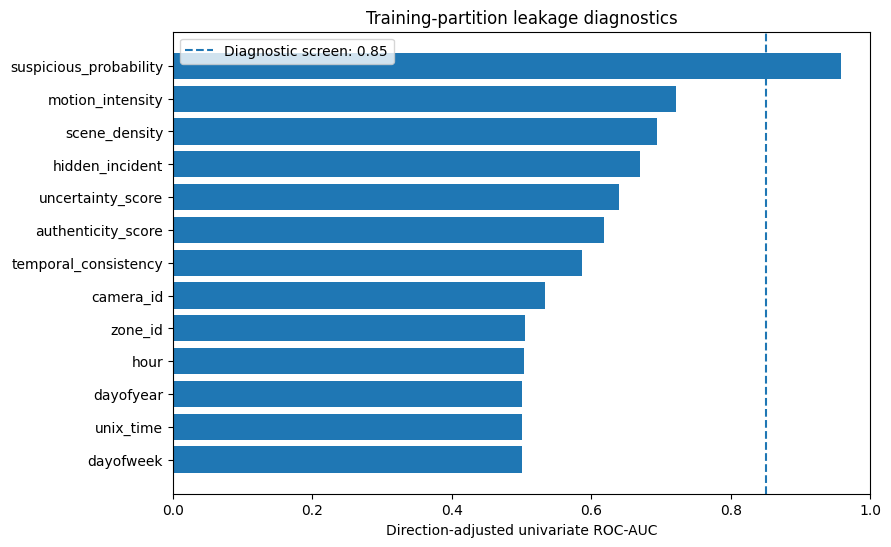

In [13]:
audit_rows = []
for column in FEATURE_SETS["full"] + ["hidden_incident", "suspicious_probability"]:
    idx = VPART["train"]
    auc = roc_auc_score(yv[idx], video_df[column].iloc[idx])
    audit_rows.append(dict(feature=column, raw_roc_auc=auc, univariate_roc_auc=max(auc, 1 - auc),
        screen_threshold=0.85, exceeds_screen=max(auc, 1 - auc) > 0.85,
        retained=column in FEATURE_SETS["full"], partition="train",
        exclusion_reason="latent state" if column == "hidden_incident" else
                         "label-generating score" if column == "suspicious_probability" else "not excluded"))
leakage_audit = pd.DataFrame(audit_rows).sort_values("univariate_roc_auc", ascending=False)
table(leakage_audit, "leakage_audit.csv", "tab_leakage_audit.tex",
      "Training-partition univariate screening. High AUC is a diagnostic flag, not proof of leakage.", "tab:leakage_audit")
fig, ax = plt.subplots(figsize=(9, 6))
a = leakage_audit.sort_values("univariate_roc_auc")
ax.barh(a.feature, a.univariate_roc_auc)
ax.axvline(0.85, linestyle="--", label="Diagnostic screen: 0.85")
ax.set(xlabel="Direction-adjusted univariate ROC-AUC", xlim=(0, 1), title="Training-partition leakage diagnostics")
ax.legend()
save_fig("fig_video_leakage_diagnostics_roc_auc.png", fig)

## Branch modeling

Model families are selected on the model-selection partition using balanced accuracy at 0.5, then ROC-AUC and log loss as tie-breakers. All operating thresholds use the separate threshold-selection partition. The primary seed is fixed; repeated fits do not select a favorable seed.

In [14]:
FITTED = {}
DEVELOPMENT_PREDICTIONS = {}
BRANCH_THRESHOLDS = {}
selection_rows = []
for branch, data, source, y, parts, feature_sets, names in (
    ("video", video_df, video_df, yv, VPART, FEATURE_SETS, CONFIG["video_models"]),
    ("cyber", Xc, cyber_df, yc, CPART, {"full": cyber_features}, CONFIG["models_to_run"]),
):
    tr = parts["train"]
    for feature_set, columns in feature_sets.items():
        for name in names:
            key = (branch, feature_set, name)
            model = estimator(name, data, columns, CONFIG["random_state"], y[tr],
                              cyber_groups[tr] if branch == "cyber" else None)
            start = time.perf_counter()
            model.fit(data.iloc[tr][columns], y[tr])
            prediction = predict_frame(model, data, columns, parts, source, branch, name, feature_set,
                                       CONFIG["random_state"], ["model_selection", "threshold_selection"])
            selected = prediction[prediction.partition == "model_selection"]
            tuning = prediction[prediction.partition == "threshold_selection"]
            threshold, reason = select_threshold(tuning.label, tuning.probability)
            row = metrics(selected.label, selected.probability, 0.5)
            selection_rows.append(dict(branch=branch, feature_set=feature_set, model=name,
                selection_partition="model_selection", threshold_partition="threshold_selection",
                threshold=threshold, threshold_rule=reason, fit_seconds=time.perf_counter() - start, **row))
            FITTED[key], DEVELOPMENT_PREDICTIONS[key], BRANCH_THRESHOLDS[key] = model, prediction, threshold
            save_csv(prediction, f"{branch}_{feature_set}_{name}_development.csv.gz", PRED_PATH)
            log(f"Fitted {branch}/{feature_set}/{name}")
selection_table = pd.DataFrame(selection_rows)
SELECTED = {}
for branch in ("cyber", "video"):
    candidates = selection_table[(selection_table.branch == branch) & (selection_table.feature_set == "full")]
    choice = candidates.sort_values(["bal_acc", "roc_auc", "log_loss", "model"], ascending=[False, False, True, True]).iloc[0]
    SELECTED[branch] = str(choice.model)
FROZEN = dict(selected_models=SELECTED,
              thresholds={"/".join(k): value for k, value in BRANCH_THRESHOLDS.items()},
              selection_rule="model_selection BA at 0.5, ROC-AUC, log loss, model name",
              graph_configuration={k: v for k, v in CONFIG.items() if k.startswith("graph_")},
              fusion_cap=CONFIG["fusion_confidence_cap"], fusion_penalty=CONFIG["fusion_uncertainty_penalty"],
              campaign_coefficients=[CONFIG["campaign_alpha"], CONFIG["campaign_beta"], CONFIG["campaign_gamma"]])
save_json(FROZEN, "frozen_model_selection.json")
table(selection_table, "branch_model_selection.csv", "tab_branch_model_selection.tex",
      "Model-selection performance and thresholds chosen on separate validation subsets.",
      latex_frame=selection_table[["branch", "feature_set", "model", "bal_acc", "roc_auc", "log_loss", "threshold"]])
log(f"Selected models: {SELECTED}")
status("model_selection", "complete", "Selections saved before primary test scoring.")

Fitted video/full/LogisticRegression
Fitted video/full/RandomForest
Fitted video/full/ExtraTrees
Fitted video/ablated/LogisticRegression
Fitted video/ablated/RandomForest
Fitted video/ablated/ExtraTrees
Fitted cyber/full/LogisticRegression
Fitted cyber/full/CalibratedLogisticRegression
Fitted cyber/full/RandomForest
Fitted cyber/full/ExtraTrees
Selected models: {'cyber': 'RandomForest', 'video': 'ExtraTrees'}
model_selection: complete. Selections saved before primary test scoring.


In [15]:
PRIMARY_PREDICTIONS = {}
primary_rows = []
for key, model in FITTED.items():
    branch, feature_set, name = key
    data, source, parts, columns = (Xc, cyber_df, CPART, cyber_features) if branch == "cyber" else (
        video_df, video_df, VPART, FEATURE_SETS[feature_set])
    prediction = predict_frame(model, data, columns, parts, source, branch, name, feature_set,
                               CONFIG["random_state"], ["test"])
    prediction["threshold"] = BRANCH_THRESHOLDS[key]
    prediction["prediction"] = (prediction.probability >= BRANCH_THRESHOLDS[key]).astype(int)
    PRIMARY_PREDICTIONS[key] = prediction
    save_csv(prediction, f"{branch}_{feature_set}_{name}_test.csv.gz", PRED_PATH)
    primary_rows.append(dict(branch=branch, feature_set=feature_set, model=name, rep=0,
        seed=CONFIG["random_state"], threshold=BRANCH_THRESHOLDS[key], scheme="primary_fixed_partition",
        **metrics(prediction.label, prediction.probability, BRANCH_THRESHOLDS[key])))
    if CONFIG["save_models"]:
        path = MODEL_PATH / f"{branch}_{feature_set}_{name}.joblib"
        joblib.dump(model, path, compress=3)
        register(path)
PRIMARY_RESULTS = pd.DataFrame(primary_rows)
save_csv(PRIMARY_RESULTS, "branch_primary_metrics.csv")

WindowsPath('F:/MBZUAI UAE/7-Elsevier-CHBR-Human-centered/GitHub-v2/Outputs/CHBR_R1_v3/tables/branch_primary_metrics.csv')

In [16]:
BRANCH_CI = {}
BRANCH_DIFFERENCES = {}
for branch in ("video", "cyber"):
    keys = [k for k in PRIMARY_PREDICTIONS if k[0] == branch]
    names = {f"{k[1]}/{k[2]}": k for k in keys}
    y = PRIMARY_PREDICTIONS[keys[0]].label.to_numpy()
    scores = {name: PRIMARY_PREDICTIONS[k].probability.to_numpy() for name, k in names.items()}
    thresholds = {name: BRANCH_THRESHOLDS[k] for name, k in names.items()}
    plan = ResamplingPlan(len(y), "block", block=CONFIG["bootstrap_block_events"], seed=CONFIG["random_state"]) if branch == "video" else ResamplingPlan(
        len(y), "cluster", groups=cyber_groups[CPART["test"]], seed=CONFIG["random_state"])
    contrasts = [(f"full/{m}", f"ablated/{m}") for m in CONFIG["video_models"]] if branch == "video" else [
        ("full/RandomForest", f"full/{m}") for m in CONFIG["models_to_run"] if m != "RandomForest"]
    ci, differences, _ = infer_family(y, scores, thresholds, plan, contrasts)
    ci[["feature_set", "model"]] = ci.name.str.split("/", expand=True)
    ci["branch"] = branch
    ci["seed"] = CONFIG["random_state"]
    BRANCH_CI[branch], BRANCH_DIFFERENCES[branch] = ci, differences
    save_csv(ci, f"{branch}_summary_ci.csv")
    if branch == "video":
        for feature_set, csv_name, tex_name, label in (
            ("full", "tab_video_full.csv", "tab_video_model_results_full.tex", "tab:video_model_results_full"),
            ("ablated", "tab_video_ablated.csv", "tab_video_model_results_strict.tex", "tab:video_model_results_strict"),
        ):
            selected = ci[ci.feature_set == feature_set]
            save_csv(selected, csv_name)
            table(interval_table(selected, ["model"]), f"{feature_set}_video_formatted.csv", tex_name,
                  "Primary chronological test performance with conditional block-bootstrap intervals.", label)
        table(differences, "tab_ablation_paired.csv", "tab_ablation_paired.tex",
              "Balanced-accuracy differences, full minus ablated. Block randomization p-values are Holm-adjusted; other metrics are in the CSV.", "tab:ablation_paired",
              latex_frame=difference_table(differences))
    else:
        table(interval_table(ci, ["model"]), "tab_cyber_model_results.csv", "tab_cyber_model_results.tex",
              "Primary grouped cyber test performance with predictor-cluster bootstrap intervals.", "tab:cyber_model_results")
        minority = ci[["model"] + [m + s for m in ("precision_benign", "recall_benign", "f1_benign") for s in ("", "_lo", "_hi")]]
        table(minority, "tab_cyber_minority.csv", "tab_cyber_minority.tex", "Benign-class performance on the primary cyber test.", "tab:cyber_minority",
              latex_frame=minority[["model", "precision_benign", "recall_benign", "f1_benign"]])
        table(differences, "cyber_paired_comparisons.csv", "tab_cyber_paired.tex", "Paired cyber balanced-accuracy differences on identical test observations; other metrics are in the CSV.", "tab:cyber_paired",
              latex_frame=difference_table(differences))
    log(f"Completed {branch} confidence intervals.")
status("branch_inference", "complete", "Conditional test intervals; no bootstrap over overlapping split scores.")

Completed video confidence intervals.
Completed cyber confidence intervals.
branch_inference: complete. Conditional test intervals; no bootstrap over overlapping split scores.


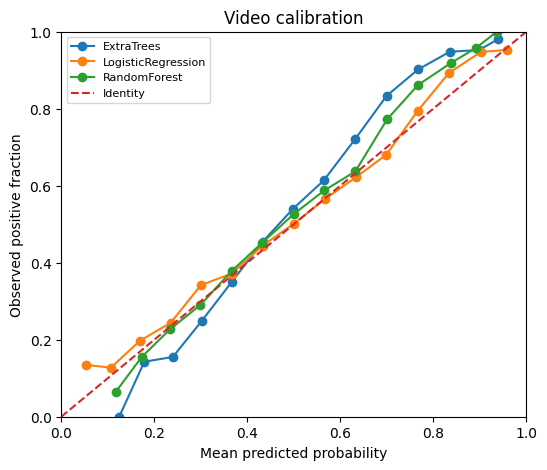

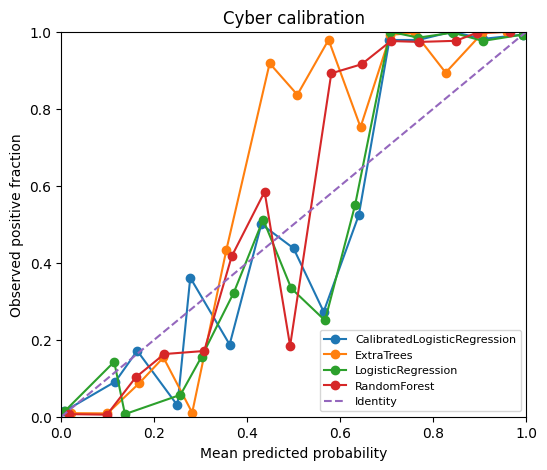

In [17]:
calibration = []
reliability = []
for key, prediction in PRIMARY_PREDICTIONS.items():
    branch, feature_set, name = key
    if feature_set != "full":
        continue
    p, y = prediction.probability.to_numpy(), prediction.label.to_numpy()
    m = metrics(y, p)
    calibration.append(dict(branch=branch, model=name, partition="test", ece=m["ece"], brier=m["brier"],
                            log_loss=m["log_loss"], mean_uncertainty=float(uncertainty_proxy(p).mean())))
    bins = np.minimum((p * 15).astype(int), 14)
    for b in range(15):
        mask = bins == b
        reliability.append(dict(branch=branch, model=name, bin=b, count=int(mask.sum()),
            mean_probability=float(p[mask].mean()) if mask.any() else np.nan,
            positive_fraction=float(y[mask].mean()) if mask.any() else np.nan))
table(pd.DataFrame(calibration), "tab_calibration.csv", "tab_calibration.tex",
      "Held-out probability calibration; uncertainty is a posterior-distance proxy.", "tab:calibration")
save_csv(pd.DataFrame(reliability), "calibration_bins.csv")
for branch in ("video", "cyber"):
    fig, ax = plt.subplots(figsize=(6, 5))
    data = pd.DataFrame(reliability)
    for name, group in data[data.branch == branch].groupby("model"):
        group = group[group["count"] > 0]
        ax.plot(group.mean_probability, group.positive_fraction, marker="o", label=name)
    ax.plot([0, 1], [0, 1], linestyle="--", label="Identity")
    ax.set(xlabel="Mean predicted probability", ylabel="Observed positive fraction", title=f"{branch.capitalize()} calibration", xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=8)
    save_fig(f"fig_{branch}_calibration.png", fig)

## Repeated fits and holdout checks

Repeated seeds use the same primary partitions. Holdout checks use only the development pool and report descriptive variation, not independent replication confidence intervals. Latent-state models are diagnostic oracles and are never selected for fusion.

In [18]:
repeated_rows = primary_rows.copy()
for rep in range(1, CONFIG["n_repetitions"]):
    seed = CONFIG["random_state"] + rep
    for key in FITTED:
        branch, feature_set, name = key
        data, y, source, parts, columns = (Xc, yc, cyber_df, CPART, cyber_features) if branch == "cyber" else (
            video_df, yv, video_df, VPART, FEATURE_SETS[feature_set])
        tr = parts["train"]
        model = estimator(name, data, columns, seed, y[tr], cyber_groups[tr] if branch == "cyber" else None)
        model.fit(data.iloc[tr][columns], y[tr])
        va = parts["threshold_selection"]
        threshold, _ = select_threshold(y[va], model.predict_proba(data.iloc[va][columns])[:, 1])
        prediction = predict_frame(model, data, columns, parts, source, branch, name, feature_set, seed, ["test"])
        prediction["threshold"] = threshold
        save_csv(prediction, f"repeated/{branch}_{feature_set}_{name}_seed{seed}.csv.gz", PRED_PATH)
        repeated_rows.append(dict(branch=branch, feature_set=feature_set, model=name, rep=rep, seed=seed,
            threshold=threshold, scheme="primary_fixed_partition", **metrics(prediction.label, prediction.probability, threshold)))
        del model
    log(f"Repeated fits: {rep + 1}/{CONFIG['n_repetitions']}")
repeated = pd.DataFrame(repeated_rows)
for branch in ("video", "cyber"):
    values = repeated[repeated.branch == branch]
    save_csv(values, f"{branch}_repetitions_raw.csv")
    save_csv(repetition_summary(values, ["feature_set", "model"]), f"{branch}_seed_variability.csv")
status("repeated_fits", "complete", f"{CONFIG['n_repetitions']} fixed-partition seeds; primary model selection unchanged.")

Repeated fits: 2/20
Repeated fits: 3/20
Repeated fits: 4/20
Repeated fits: 5/20
Repeated fits: 6/20
Repeated fits: 7/20
Repeated fits: 8/20
Repeated fits: 9/20
Repeated fits: 10/20
Repeated fits: 11/20
Repeated fits: 12/20
Repeated fits: 13/20
Repeated fits: 14/20
Repeated fits: 15/20
Repeated fits: 16/20
Repeated fits: 17/20
Repeated fits: 18/20
Repeated fits: 19/20
Repeated fits: 20/20
repeated_fits: complete. 20 fixed-partition seeds; primary model selection unchanged.


In [19]:
hidden_rows = []
for feature_set, columns in FEATURE_SETS.items():
    for name in CONFIG["video_models"]:
        tr, va, te = VPART["train"], VPART["threshold_selection"], VPART["test"]
        oracle_columns = columns + ["hidden_incident"]
        model = estimator(name, video_df, oracle_columns, CONFIG["random_state"])
        model.fit(video_df.iloc[tr][oracle_columns], yv[tr])
        threshold, _ = select_threshold(yv[va], model.predict_proba(video_df.iloc[va][oracle_columns])[:, 1])
        oracle_score = model.predict_proba(video_df.iloc[te][oracle_columns])[:, 1]
        valid = PRIMARY_PREDICTIONS[("video", feature_set, name)]
        plan = ResamplingPlan(len(te), "block", CONFIG["bootstrap_block_events"], seed=CONFIG["random_state"])
        _, difference, _ = infer_family(yv[te], {"latent_oracle": oracle_score, "observable": valid.probability.to_numpy()},
            {"latent_oracle": threshold, "observable": BRANCH_THRESHOLDS[("video", feature_set, name)]}, plan,
            [("latent_oracle", "observable")])
        difference["feature_set"], difference["model"] = feature_set, name
        hidden_rows.append(difference)
        save_csv(pd.DataFrame({"source_row_id": video_df.source_row_id.iloc[te], "label": yv[te],
                              "probability": oracle_score, "threshold": threshold}),
                 f"diagnostic_latent_{feature_set}_{name}.csv.gz", PRED_PATH)
        del model
hidden_effect = pd.concat(hidden_rows, ignore_index=True)
hidden_p = hidden_effect.p_value.notna()
hidden_effect.loc[hidden_p, "p_holm"] = holm(hidden_effect.loc[hidden_p, "p_value"].to_numpy())
table(hidden_effect, "tab_hidden_incident_effect.csv", "tab_hidden_incident_effect.tex",
      "Balanced-accuracy differences, latent oracle minus observable predictors. Latent models are diagnostic only; other metrics are in the CSV.", "tab:hidden_incident_effect",
      latex_frame=difference_table(hidden_effect, ["feature_set", "model"]))

,comparison,a,b,metric,mean_diff,ci_lo,ci_hi,valid_bootstrap,p_value,p_holm,feature_set,model
0,latent_oracle - observable,latent_oracle,observable,accuracy,-0.001775,-0.005864,0.002469,2000,NaN,NaN,full,LogisticRegression
1,latent_oracle - observable,latent_oracle,observable,bal_acc,0.001588,-0.002418,0.005606,2000,0.456772,0.569715,full,LogisticRegression
2,latent_oracle - observable,latent_oracle,observable,precision,0.030335,0.025910,0.034827,2000,NaN,NaN,full,LogisticRegression
3,latent_oracle - observable,latent_oracle,observable,recall,-0.056293,-0.062290,-0.050550,2000,NaN,NaN,full,LogisticRegression
4,latent_oracle - observable,latent_oracle,observable,f1,-0.018757,-0.023124,-0.014303,2000,NaN,NaN,full,LogisticRegression
...,...,...,...,...,...,...,...,...,...,...,...,...
79,latent_oracle - observable,latent_oracle,observable,recall_benign,0.019332,0.014651,0.024030,2000,NaN,NaN,ablated,ExtraTrees
80,latent_oracle - observable,latent_oracle,observable,f1_benign,0.012138,0.009029,0.015348,2000,NaN,NaN,ablated,ExtraTrees
81,latent_oracle - observable,latent_oracle,observable,brier,-0.010011,-0.011334,-0.008739,2000,NaN,NaN,ablated,ExtraTrees
82,latent_oracle - observable,latent_oracle,observable,log_loss,-0.031836,-0.035711,-0.028210,2000,NaN,NaN,ablated,ExtraTrees


In [20]:
def development_split(branch, scheme, rep):
    seed = CONFIG["random_state"] + 300 + rep
    if branch == "video":
        pool = np.sort(np.concatenate([VPART[r] for r in ("train", "model_selection", "threshold_selection")]))
        labels = yv[pool]
        if scheme == "camera_group":
            groups = video_df.camera_id.iloc[pool].to_numpy()
            unique = np.random.default_rng(seed).permutation(np.unique(groups))
            n_test = max(1, int(round(0.3 * len(unique))))
            n_val = max(1, int(round(0.1 * len(unique))))
            te = np.flatnonzero(np.isin(groups, unique[:n_test]))
            va = np.flatnonzero(np.isin(groups, unique[n_test:n_test + n_val]))
            tr = np.flatnonzero(~np.isin(groups, unique[:n_test + n_val]))
        else:
            trva, te = train_test_split(np.arange(len(pool)), test_size=0.3, stratify=labels, random_state=seed)
            tr, va = train_test_split(trva, test_size=1 / 7, stratify=labels[trva], random_state=seed)
        return pool[tr], pool[va], pool[te]
    pool = np.sort(np.concatenate([CPART[r] for r in ("train", "model_selection", "threshold_selection")]))
    parts = grouped_partition(yc[pool], cyber_groups[pool], seed)
    return pool[parts["train"]], pool[np.r_[parts["model_selection"], parts["threshold_selection"]]], pool[parts["test"]]


holdout_rows, holdout_membership = [], []
for branch, schemes in (("video", ["stratified", "camera_group"]), ("cyber", ["grouped_stratified"])):
    data, y, source, sets, names = (video_df, yv, video_df, FEATURE_SETS, CONFIG["video_models"]) if branch == "video" else (
        Xc, yc, cyber_df, {"full": cyber_features}, CONFIG["models_to_run"])
    for scheme in schemes:
        for rep in range(CONFIG["n_holdout_repetitions"]):
            tr, va, te = development_split(branch, scheme, rep)
            assert not np.intersect1d(te, (VPART if branch == "video" else CPART)["test"]).size
            for role, ids in (("train", tr), ("validation", va), ("evaluation", te)):
                holdout_membership.append(pd.DataFrame({"branch": branch, "scheme": scheme, "rep": rep,
                    "source_row_id": source.source_row_id.iloc[ids].to_numpy(), "partition": role}))
            for feature_set, columns in sets.items():
                for name in names:
                    seed = CONFIG["random_state"] + 300 + rep
                    model = estimator(name, data, columns, seed, y[tr], cyber_groups[tr] if branch == "cyber" else None)
                    model.fit(data.iloc[tr][columns], y[tr])
                    threshold, reason = select_threshold(y[va], model.predict_proba(data.iloc[va][columns])[:, 1])
                    score = model.predict_proba(data.iloc[te][columns])[:, 1]
                    holdout_rows.append(dict(branch=branch, scheme=scheme, rep=rep, model=name, feature_set=feature_set,
                        pool="development_only", threshold=threshold, threshold_rule=reason, **metrics(y[te], score, threshold)))
                    save_csv(pd.DataFrame({"source_row_id": source.source_row_id.iloc[te].to_numpy(), "label": y[te],
                        "probability": score, "threshold": threshold}), f"holdouts/{branch}_{scheme}_{feature_set}_{name}_{rep}.csv.gz", PRED_PATH)
                    del model
            log(f"Development holdout: {branch}/{scheme}, {rep + 1}/{CONFIG['n_holdout_repetitions']}")
if holdout_rows:
    holdouts = pd.DataFrame(holdout_rows)
    save_csv(pd.concat(holdout_membership, ignore_index=True), "development_holdout_membership.csv.gz")
    save_csv(holdouts[holdouts.branch == "cyber"], "cyber_holdout_repetitions.csv")
    video_all = pd.concat([repeated[repeated.branch == "video"], holdouts[holdouts.branch == "video"]], ignore_index=True)
    save_csv(video_all, "video_repetitions_all_schemes.csv")
    holdout_summary = repetition_summary(holdouts, ["branch", "scheme", "feature_set", "model"])
    table(holdout_summary, "tab_holdout_schemes.csv", "tab_holdout_schemes.tex",
          "Development-pool holdout sensitivity: descriptive means and standard deviations, not independent replication intervals.", "tab:holdout_schemes",
          latex_frame=variability_table(holdout_summary, ["branch", "scheme", "feature_set", "model"]))
status("holdout_sensitivity", "complete", "All alternative holdouts restricted to development observations.")

Development holdout: video/stratified, 1/10
Development holdout: video/stratified, 2/10
Development holdout: video/stratified, 3/10
Development holdout: video/stratified, 4/10
Development holdout: video/stratified, 5/10
Development holdout: video/stratified, 6/10
Development holdout: video/stratified, 7/10
Development holdout: video/stratified, 8/10
Development holdout: video/stratified, 9/10
Development holdout: video/stratified, 10/10
Development holdout: video/camera_group, 1/10
Development holdout: video/camera_group, 2/10
Development holdout: video/camera_group, 3/10
Development holdout: video/camera_group, 4/10
Development holdout: video/camera_group, 5/10
Development holdout: video/camera_group, 6/10
Development holdout: video/camera_group, 7/10
Development holdout: video/camera_group, 8/10
Development holdout: video/camera_group, 9/10
Development holdout: video/camera_group, 10/10
Development holdout: cyber/grouped_stratified, 1/10
Development holdout: cyber/grouped_stratified,

## Score fusion

For present modalities, weights are proportional to `min(1 - mean_event_uncertainty, cap)`. Zero total confidence gives equal weights over present modalities. The adjusted score is `clip(weighted_probability - penalty * weighted_uncertainty, 0, 1)`. Missing modalities receive zero weight; no observations produce an abstention. The score is not asserted to be a calibrated event probability or a variational optimum.

In [21]:
def fusion_arrays(frame):
    p = frame[["cyber_mean_prob", "video_mean_prob"]].to_numpy(float)
    u = frame[["cyber_mean_uncertainty", "video_mean_uncertainty"]].to_numpy(float)
    present = frame[["cyber_count", "video_count"]].to_numpy() > 0
    if np.any(present & (~np.isfinite(p) | ~np.isfinite(u))):
        raise ValueError("A present modality has a missing score or uncertainty.")
    if np.any(present & ((p < 0) | (p > 1) | (u < 0) | (u > 1))):
        raise ValueError("Present probabilities and ambiguities must lie in [0, 1].")
    return np.where(present, p, 0.0), np.where(present, u, 1.0), present


def normalized_weights(confidence, present):
    confidence = np.where(present, confidence, 0.0)
    total = confidence.sum(axis=1, keepdims=True)
    count = present.sum(axis=1, keepdims=True)
    equal = np.divide(present.astype(float), count, out=np.zeros_like(confidence), where=count > 0)
    return np.divide(confidence, total, out=equal.copy(), where=total > 1e-15)


def weighted_fusion(frame, cap=1.0, penalty=0.0, fixed_weights=None, from_mean=False):
    p, u, present = fusion_arrays(frame)
    if from_mean:
        u = np.where(present, uncertainty_proxy(p), 1.0)
    confidence = np.minimum(1 - u, cap) if fixed_weights is None else np.broadcast_to(fixed_weights, p.shape).copy()
    weights = normalized_weights(confidence, present)
    raw = np.sum(weights * p, axis=1)
    uncertainty = np.sum(weights * u, axis=1)
    score = np.clip(raw - penalty * uncertainty, 0, 1)
    absent = ~present.any(axis=1)
    raw[absent], uncertainty[absent], score[absent] = np.nan, np.nan, np.nan
    return score, raw, uncertainty, weights


def dempster_shafer(frame, discounted=False):
    """Binary singleton/ignorance masses; full conflict falls back to vacuous belief."""
    p, u, present = fusion_arrays(frame)
    reliability = np.where(present, 1 - u if discounted else 1.0, 0.0)
    positive, negative, ignorance = reliability * p, reliability * (1 - p), 1 - reliability
    one = positive[:, 0] * positive[:, 1] + positive[:, 0] * ignorance[:, 1] + ignorance[:, 0] * positive[:, 1]
    zero = negative[:, 0] * negative[:, 1] + negative[:, 0] * ignorance[:, 1] + ignorance[:, 0] * negative[:, 1]
    unknown = ignorance[:, 0] * ignorance[:, 1]
    total = one + zero + unknown
    conflict = positive[:, 0] * negative[:, 1] + negative[:, 0] * positive[:, 1]
    score = np.divide(one + 0.5 * unknown, total, out=np.full(len(frame), 0.5), where=total > 1e-12)
    score[~present.any(axis=1)] = np.nan
    return np.clip(score, 0, 1), conflict


FUSION_METHODS = ["CyberOnly", "VideoOnly", "AvailabilityOnly", "AlwaysPositive", "AlwaysNegative", "Mean", "Maximum",
    "FixedCyber75", "FixedCyber25", "ConfidenceUncapped", "ConfidenceCapped", "ConfidencePenalty",
    "DempsterShafer", "DiscountedDempsterShafer", "UVIF"]


def fit_fusion_controls(validation, target):
    y = validation[target].to_numpy()
    prior = float(y.mean()) if len(y) else 0.5
    availability = (validation.cyber_count.gt(0).astype(int) * 2 + validation.video_count.gt(0).astype(int)).to_numpy()
    lookup = {}
    for state in range(4):
        mask = availability == state
        lookup[state] = float((y[mask].sum() + prior) / (mask.sum() + 1))
    return {"prior": prior, "availability": lookup}


def score_fusion_methods(frame, controls):
    p, u, present = fusion_arrays(frame)
    any_present = present.any(axis=1)
    scores = {
        "CyberOnly": np.where(present[:, 0], p[:, 0], controls["prior"]),
        "VideoOnly": np.where(present[:, 1], p[:, 1], controls["prior"]),
        "AvailabilityOnly": np.array([controls["availability"][int(a) * 2 + int(b)] for a, b in present]),
        "AlwaysPositive": np.ones(len(frame)), "AlwaysNegative": np.zeros(len(frame)),
        "Mean": weighted_fusion(frame, fixed_weights=[0.5, 0.5])[0],
        "Maximum": np.max(np.where(present, p, -np.inf), axis=1),
        "FixedCyber75": weighted_fusion(frame, fixed_weights=[0.75, 0.25])[0],
        "FixedCyber25": weighted_fusion(frame, fixed_weights=[0.25, 0.75])[0],
        "ConfidenceUncapped": weighted_fusion(frame)[0],
        "ConfidenceCapped": weighted_fusion(frame, cap=CONFIG["fusion_confidence_cap"])[0],
        "ConfidencePenalty": weighted_fusion(frame, penalty=CONFIG["fusion_uncertainty_penalty"])[0],
        "DempsterShafer": dempster_shafer(frame)[0],
        "DiscountedDempsterShafer": dempster_shafer(frame, discounted=True)[0],
        "UVIF": weighted_fusion(frame, cap=CONFIG["fusion_confidence_cap"], penalty=CONFIG["fusion_uncertainty_penalty"])[0],
    }
    for name in scores:
        scores[name] = np.asarray(scores[name], float)
        scores[name][~any_present] = np.nan
    return scores

In [22]:
def ordered_events(prediction, branch, start=None, ordering="native", seed=42):
    data = prediction.sort_values("source_row_id").copy().reset_index(drop=True)
    if branch == "cyber":
        if ordering == "random":
            order = np.random.default_rng(seed).permutation(len(data))
            data = data.iloc[order].reset_index(drop=True)
        elif ordering == "score_interleaved":
            ranked = np.argsort(data.probability.to_numpy(), kind="stable")
            low, high = ranked[:len(ranked) // 2], ranked[len(ranked) // 2:][::-1]
            order = np.column_stack([high[:len(low)], low]).ravel()
            if len(high) > len(low):
                order = np.r_[order, high[-1]]
            data = data.iloc[order].reset_index(drop=True)
        elif ordering != "native":
            raise ValueError(ordering)
        data["timestamp"] = pd.date_range(pd.Timestamp(start), periods=len(data), freq=pd.Timedelta(seconds=CONFIG["surrogate_cyber_spacing_seconds"]))
    else:
        data = data.sort_values("timestamp").reset_index(drop=True)
        data["timestamp"] = pd.to_datetime(data.timestamp)
    return data[["source_row_id", "timestamp", "probability", "uncertainty", "label"]].copy()


def window_ids(timestamps, seconds):
    origin = pd.Timestamp(CONFIG["window_origin"]).value
    return ((pd.to_datetime(timestamps).astype("int64").to_numpy() - origin) // (int(seconds) * 10**9)).astype(np.int64)


def build_fusion_table(cyber_events, video_events, seconds, truth=None):
    frames = []
    for branch, events in (("cyber", cyber_events), ("video", video_events)):
        e = events.copy()
        e["window_id"] = window_ids(e.timestamp, seconds)
        group = e.groupby("window_id").agg(mean_prob=("probability", "mean"), mean_uncertainty=("uncertainty", "mean"),
                                          count=("probability", "size"), label_any=("label", "max"))
        frames.append(group.add_prefix(branch + "_"))
    table = frames[0].join(frames[1], how="outer").sort_index()
    if truth is not None:
        table = table.reindex(truth.window_id.to_numpy())
        table.index.name = "window_id"
    for branch in ("cyber", "video"):
        table[branch + "_count"] = table[branch + "_count"].astype(float).fillna(0).astype(int)
        table[branch + "_label_any"] = table[branch + "_label_any"].astype(float).fillna(0).astype(int)
    table = table.reset_index()
    table["window_start"] = pd.Timestamp(CONFIG["window_origin"]) + pd.to_timedelta(table.window_id * seconds, unit="s")
    table["modality_count"] = table.cyber_count.gt(0).astype(int) + table.video_count.gt(0).astype(int)
    table["target_or"] = np.maximum(table.cyber_label_any, table.video_label_any)
    table["target_and"] = np.minimum(table.cyber_label_any, table.video_label_any)
    if truth is not None:
        reference = truth.set_index("window_id").loc[table.window_id]
        for column in ("cyber_label_any", "video_label_any", "target_or", "target_and"):
            table[column] = reference[column].to_numpy()
    table["disagree"] = table.cyber_label_any.ne(table.video_label_any) & table.modality_count.eq(2)
    score, raw, uncertainty, weights = weighted_fusion(table, CONFIG["fusion_confidence_cap"], CONFIG["fusion_uncertainty_penalty"])
    table["w_cyber"], table["w_video"] = weights[:, 0], weights[:, 1]
    table["adjusted_fusion_score"], table["raw_fusion_score"], table["fusion_uncertainty"] = score, raw, uncertainty
    table["both_capped"] = table.modality_count.eq(2) & (1 - table.cyber_mean_uncertainty >= CONFIG["fusion_confidence_cap"]) & (1 - table.video_mean_uncertainty >= CONFIG["fusion_confidence_cap"])
    table["ds_conflict"] = dempster_shafer(table)[1]
    return table


def set_window_states(frame, threshold):
    out = frame.copy()
    risky = out.adjusted_fusion_score >= threshold
    uncertain = out.fusion_uncertainty >= CONFIG["window_uncertainty_threshold"]
    out["fused_pred"] = np.where(out.modality_count > 0, risky.astype(float), np.nan)
    out["window_state"] = np.select(
        [out.modality_count.eq(0), out.modality_count.eq(1), risky & uncertain, risky, uncertain],
        ["no_observation", "single_modality_only", "high_risk_uncertain", "high_risk", "uncertain"], default="low_risk")
    return out


def composition(frame, protocol, partition):
    group = frame.assign(cyber_present=frame.cyber_count > 0, video_present=frame.video_count > 0).groupby(
        ["cyber_present", "video_present", "target_or", "target_and"], dropna=False).size().rename("count").reset_index()
    group["protocol"], group["partition"] = protocol, partition
    return group

In [23]:
def evaluate_fusion(validation, test, protocol, seconds=120, with_intervals=False):
    results, differences, records, configurations = [], [], [], {}
    for target in ("target_or", "target_and"):
        controls = fit_fusion_controls(validation, target)
        va_scores, te_scores = score_fusion_methods(validation, controls), score_fusion_methods(test, controls)
        thresholds = {}
        reasons = {}
        for method in FUSION_METHODS:
            if method in ("AlwaysPositive", "AlwaysNegative"):
                thresholds[method], reasons[method] = 0.5, "fixed_control"
            else:
                thresholds[method], reasons[method] = select_threshold(validation[target], va_scores[method])
        configurations[target] = dict(controls=controls, thresholds=thresholds, reasons=reasons)
        common = test.modality_count.to_numpy() > 0
        if with_intervals and common.all() and len(test):
            plan = ResamplingPlan(len(test), "block", max(1, int(math.ceil(CONFIG["fusion_bootstrap_block_seconds"] / seconds))), seed=CONFIG["random_state"])
            contrasts = [("UVIF", method) for method in FUSION_METHODS if method != "UVIF"]
            ci, diff, _ = infer_family(test[target], te_scores, thresholds, plan, contrasts)
            ci = ci.rename(columns={"name": "method"})
            ci["target"], ci["protocol"], ci["subset"] = target, protocol, "all_observed"
            ci["coverage"], ci["n_total"], ci["n_scored"] = 1.0, len(test), len(test)
            results.extend(ci.to_dict("records"))
            diff["target"], diff["protocol"] = target, protocol
            differences.extend(diff.to_dict("records"))
        else:
            for method in FUSION_METHODS:
                results.append(dict(protocol=protocol, target=target, subset="all_observed", method=method,
                    threshold=thresholds[method], threshold_rule=reasons[method], **metrics(test[target], te_scores[method], thresholds[method])))
        subsets = {
            "dual_modality": test.modality_count.eq(2).to_numpy(),
            "cyber_only": (test.cyber_count.gt(0) & test.video_count.eq(0)).to_numpy(),
            "video_only": (test.cyber_count.eq(0) & test.video_count.gt(0)).to_numpy(),
            "truth_disagreement": test.disagree.to_numpy(),
        }
        for subset, mask in subsets.items():
            if mask.any():
                for method in FUSION_METHODS:
                    results.append(dict(protocol=protocol, target=target, subset=subset, method=method,
                        threshold=thresholds[method], **metrics(test[target].to_numpy()[mask], te_scores[method][mask], thresholds[method])))
        for partition, frame, score_map in (("threshold_selection", validation, va_scores), ("test", test, te_scores)):
            record = frame[["window_id", target]].copy().rename(columns={target: "label"})
            record["partition"], record["target"], record["protocol"] = partition, target, protocol
            for method, score in score_map.items():
                record[method + "_score"] = score
                record[method + "_threshold"] = thresholds[method]
            records.append(record)
    return pd.DataFrame(results), pd.DataFrame(differences), pd.concat(records, ignore_index=True), configurations

## Window evaluation

Each modality contributes its own predictions for the threshold-selection and test partitions. Cyber time starts at the corresponding surveillance-partition start with 20-second spacing. Window targets are the OR or AND of constituent labels. They are constructed evaluation targets, not independent campaign annotations.

In [24]:
EVENTS = {}
for role in ("threshold_selection", "test"):
    video_key = ("video", "full", SELECTED["video"])
    cyber_key = ("cyber", "full", SELECTED["cyber"])
    vpred = PRIMARY_PREDICTIONS[video_key] if role == "test" else DEVELOPMENT_PREDICTIONS[video_key].query("partition == @role")
    cpred = PRIMARY_PREDICTIONS[cyber_key] if role == "test" else DEVELOPMENT_PREDICTIONS[cyber_key].query("partition == @role")
    ve = ordered_events(vpred, "video")
    ce = ordered_events(cpred, "cyber", start=ve.timestamp.min())
    EVENTS[role] = (ce, ve)
    save_csv(ce, f"cyber_events_{role}.csv.gz", PRED_PATH)
    save_csv(ve, f"video_events_{role}.csv.gz", PRED_PATH)
validation_window = build_fusion_table(*EVENTS["threshold_selection"], CONFIG["fusion_window_seconds"])
ftab = build_fusion_table(*EVENTS["test"], CONFIG["fusion_window_seconds"])
fusion_results, fusion_differences, fusion_predictions, FUSION_CONFIG = evaluate_fusion(
    validation_window, ftab, "window", CONFIG["fusion_window_seconds"], with_intervals=True)
theta = FUSION_CONFIG["target_or"]["thresholds"]["UVIF"]
ftab = set_window_states(ftab, theta)
validation_window = set_window_states(validation_window, theta)
ftab["partition"], validation_window["partition"] = "test", "threshold_selection"
save_csv(ftab, "fusion_window_table.csv")
save_csv(validation_window, "fusion_window_validation_table.csv")
save_csv(fusion_predictions, "fusion_predictions.csv.gz", PRED_PATH)
save_json(FUSION_CONFIG, "fusion_thresholds.json")
table(fusion_results, "fusion_baselines_raw.csv", "tab_fusion_baselines.tex",
      "Matched fusion comparisons for the OR target on all observed test windows. Conditional bootstrap intervals are shown.", "tab:fusion_baselines",
      latex_frame=interval_table(fusion_results.query("target == 'target_or' and subset == 'all_observed'"), ["method"]))
table(fusion_differences, "fusion_paired_comparisons.csv", "tab_fusion_paired.tex",
      "Paired balanced-accuracy differences for the OR target, UVIF minus comparator. Full metric differences are in the CSV.",
      latex_frame=difference_table(fusion_differences.query("target == 'target_or'")))
composition_table = pd.concat([composition(validation_window, "window", "threshold_selection"), composition(ftab, "window", "test")], ignore_index=True)
table(composition_table, "fusion_availability_composition.csv", "tab_fusion_availability.tex",
      "Target composition conditional on modality availability.")
save_json(dict(fusion_rows=len(ftab), validation_rows=len(validation_window), theta=theta,
    tau_c=BRANCH_THRESHOLDS[cyber_key], tau_v=BRANCH_THRESHOLDS[video_key],
    dual_modality_windows=int(ftab.modality_count.eq(2).sum()), single_modality_windows=int(ftab.modality_count.eq(1).sum()),
    both_capped_fraction=float(ftab.both_capped.mean()), window_states=ftab.window_state.value_counts().to_dict(),
    selected_models=SELECTED, target="OR of constituent labels", temporal_status="surrogate cyber; generated surveillance",
    test_rows_not_used_for_selection=True), "fusion_summary.json")
status("window_fusion", "complete", f"{len(ftab)} test windows; separate validation windows used for all thresholds.")
display(fusion_results.query("target == 'target_or' and subset == 'all_observed'")[["method", "bal_acc", "roc_auc", "pr_auc", "f1", "fpr"]])

window_fusion: complete. 12961 test windows; separate validation windows used for all thresholds.


,method,bal_acc,roc_auc,pr_auc,f1,fpr
0,CyberOnly,0.848260,0.845172,0.950288,0.821116,0.000000
1,VideoOnly,0.642369,0.695932,0.904228,0.582847,0.141452
2,AvailabilityOnly,0.727038,0.727038,0.879081,0.858673,0.369516
3,AlwaysPositive,0.500000,0.500000,0.796003,0.886416,1.000000
4,AlwaysNegative,0.500000,0.500000,0.796003,0.000000,0.000000
5,Mean,0.864600,0.908740,0.974093,0.875865,0.062405
6,Maximum,0.893786,0.939800,0.985347,0.900643,0.040091
7,FixedCyber75,0.876623,0.897282,0.974152,0.873665,0.027988
8,FixedCyber25,0.792849,0.870096,0.957778,0.879612,0.249622
9,ConfidenceUncapped,0.870774,0.903318,0.976271,0.874690,0.044629


## Controlled paired-score diagnostic

One-to-one pairs are sampled without labels and without replacement within each repetition. Unused cyber records are identified in the pairing manifest. This diagnostic removes window-occupancy aggregation; it does not establish physical-cyber correspondence.

In [25]:
def paired_score_frame(cyber_events, video_events, seed):
    rng = np.random.default_rng(seed)
    n = min(len(cyber_events), len(video_events))
    ci = rng.choice(len(cyber_events), n, replace=False)
    vi = np.sort(rng.choice(len(video_events), n, replace=False))
    c, v = cyber_events.iloc[ci].reset_index(drop=True), video_events.iloc[vi].reset_index(drop=True)
    frame = pd.DataFrame(dict(window_id=np.arange(n), cyber_mean_prob=c.probability, video_mean_prob=v.probability,
        cyber_mean_uncertainty=c.uncertainty, video_mean_uncertainty=v.uncertainty, cyber_count=1, video_count=1,
        cyber_label_any=c.label, video_label_any=v.label, modality_count=2,
        target_or=np.maximum(c.label, v.label), target_and=np.minimum(c.label, v.label), disagree=c.label.ne(v.label),
        cyber_source_row_id=c.source_row_id, video_source_row_id=v.source_row_id, video_timestamp=v.timestamp))
    used_c, used_v = set(c.source_row_id), set(v.source_row_id)
    manifest = pd.concat([
        pd.DataFrame({"branch": "cyber", "source_row_id": cyber_events.source_row_id,
                      "paired": cyber_events.source_row_id.isin(used_c)}),
        pd.DataFrame({"branch": "video", "source_row_id": video_events.source_row_id,
                      "paired": video_events.source_row_id.isin(used_v)}),
    ], ignore_index=True)
    return frame, manifest


paired_results = []
for rep in range(CONFIG["paired_diagnostic_repetitions"]):
    seed = CONFIG["random_state"] + 1000 + rep
    validation_pair, vm = paired_score_frame(*EVENTS["threshold_selection"], seed)
    test_pair, tm = paired_score_frame(*EVENTS["test"], seed + 100)
    result, difference, record, _ = evaluate_fusion(validation_pair, test_pair, f"paired_{rep}",
                                                  int(pd.to_timedelta(CONFIG["video_event_freq"]).total_seconds()), with_intervals=rep == 0)
    result["rep"] = rep
    paired_results.append(result)
    save_csv(test_pair, f"pairing_{rep}_test.csv.gz", PRED_PATH)
    save_csv(validation_pair, f"pairing_{rep}_validation.csv.gz", PRED_PATH)
    save_csv(pd.concat([vm.assign(partition="threshold_selection"), tm.assign(partition="test")]), f"pairing_{rep}_membership.csv.gz", PRED_PATH)
    save_csv(record, f"paired_{rep}_predictions.csv.gz", PRED_PATH)
    if rep == 0:
        save_csv(difference, "paired_fusion_comparisons.csv")
        save_csv(pd.concat([composition(validation_pair, "paired", "threshold_selection"), composition(test_pair, "paired", "test")]), "paired_availability_composition.csv")
paired_results = pd.concat(paired_results, ignore_index=True)
table(paired_results, "paired_fusion_baselines.csv", "tab_paired_fusion_baselines.tex",
      "Label-blind paired-score diagnostic for the OR target, first fixed pairing. Conditional bootstrap intervals are shown.",
      latex_frame=interval_table(paired_results.query("rep == 0 and target == 'target_or' and subset == 'all_observed'"), ["method"]))
save_csv(repetition_summary(paired_results[paired_results.subset == "all_observed"], ["target", "method"]), "paired_fusion_variability.csv")
status("paired_diagnostic", "complete", "Label-blind pairs, explicit used/unused records, no event correspondence claim.")

paired_diagnostic: complete. Label-blind pairs, explicit used/unused records, no event correspondence claim.


## Evidence graph

An undirected simple graph links retained alerts to active window hubs. Similarity links are within-modality cosine similarities of `(probability, uncertainty)`; these are score similarities, not semantic or causal links. Temporal links join consecutive same-modality alerts. Sparse edge values encode membership (1), similarity (2), and temporal (4); an edge present in several families is counted once.

In [26]:
def edge_matrix(rows, cols, n, value):
    rows, cols = np.asarray(rows, np.int32), np.asarray(cols, np.int32)
    low, high = np.minimum(rows, cols), np.maximum(rows, cols)
    keep = low != high
    matrix = sparse.coo_matrix((np.ones(keep.sum(), np.uint8), (low[keep], high[keep])), shape=(n, n)).tocsr()
    matrix.sum_duplicates()
    matrix.data[:] = value
    return matrix


def graph_nodes(cyber_events, video_events, frame, seconds):
    parts = []
    for branch, events in (("cyber", cyber_events), ("video", video_events)):
        threshold = BRANCH_THRESHOLDS[(branch, "full", SELECTED[branch])]
        alerts = events[events.probability >= threshold].copy()
        alerts["window_id"] = window_ids(alerts.timestamp, seconds)
        alerts = alerts[alerts.window_id.isin(frame.window_id)].sort_values(["timestamp", "source_row_id"]).reset_index(drop=True)
        alerts["node_key"] = branch + ":" + alerts.source_row_id.astype(str)
        alerts["node_type"], alerts["modality"] = "evidence", branch
        parts.append(alerts[["node_key", "node_type", "modality", "source_row_id", "timestamp", "window_id", "probability", "uncertainty"]])
    evidence = pd.concat(parts, ignore_index=True)
    hub_windows = np.sort(evidence.window_id.unique()) if CONFIG["graph_hub_policy"] == "alert_windows" else frame.window_id.to_numpy()
    hubs = frame.set_index("window_id").loc[hub_windows].reset_index()
    hubs = pd.DataFrame({"node_key": [f"hub:{seconds}:{x}" for x in hub_windows], "node_type": "hub", "modality": "hub",
        "source_row_id": -1, "timestamp": hubs.window_start, "window_id": hub_windows,
        "probability": hubs.adjusted_fusion_score, "uncertainty": hubs.fusion_uncertainty})
    nodes = pd.concat([evidence, hubs], ignore_index=True)
    nodes.insert(0, "node_id", np.arange(len(nodes), dtype=np.int32))
    nodes["similarity_sampled"] = False
    assert nodes.node_key.is_unique
    return nodes


def build_graph(cyber_events, video_events, frame, seconds, parameters=None):
    params = dict(similarity_threshold=CONFIG["graph_similarity_threshold"], sample_cap=CONFIG["graph_max_similarity_sample"],
                  temporal_seconds=CONFIG["graph_temporal_edge_seconds"],
                  similarity_time_limit=CONFIG["graph_similarity_time_limit_seconds"])
    params.update(parameters or {})
    nodes = graph_nodes(cyber_events, video_events, frame, seconds)
    n = len(nodes)
    evidence = nodes[nodes.node_type == "evidence"]
    hub_index = nodes[nodes.node_type == "hub"].set_index("window_id").node_id
    wr = evidence.node_id.to_numpy(np.int32)
    wc = evidence.window_id.map(hub_index).to_numpy(np.int32)
    membership = edge_matrix(wr, wc, n, 1)
    similarity_rows, similarity_cols, temporal_rows, temporal_cols = [], [], [], []
    for branch, seed_offset in (("cyber", 0), ("video", 1)):
        group = evidence[evidence.modality == branch].sort_values("source_row_id")
        count = min(int(params["sample_cap"]), len(group))
        if CONFIG["graph_similarity_sampling"] == "seeded_uniform":
            selected_positions = np.random.default_rng(CONFIG["random_state"] + seed_offset).permutation(len(group))[:count]
        else:
            raise ValueError("graph_similarity_sampling must be seeded_uniform.")
        selected = group.iloc[selected_positions].sort_values("node_id")
        nodes.loc[selected.node_id, "similarity_sampled"] = True
        ids = selected.node_id.to_numpy(np.int32)
        vectors = selected[["probability", "uncertainty"]].to_numpy(float)
        norms = np.linalg.norm(vectors, axis=1, keepdims=True)
        vectors = np.divide(vectors, norms, out=np.zeros_like(vectors), where=norms > 0)
        timestamps = pd.to_datetime(selected.timestamp).astype("int64").to_numpy()
        chunk = CONFIG["graph_similarity_chunk_size"]
        for start in range(0, len(ids), chunk):
            end = min(start + chunk, len(ids))
            similarity = vectors[start:end] @ vectors.T
            hit = similarity >= params["similarity_threshold"]
            hit &= np.arange(start, end)[:, None] < np.arange(len(ids))[None, :]
            if params["similarity_time_limit"] is not None:
                hit &= np.abs(timestamps[start:end, None] - timestamps[None, :]) <= params["similarity_time_limit"] * 10**9
            r, c = np.nonzero(hit)
            similarity_rows.append(ids[r + start])
            similarity_cols.append(ids[c])
        consecutive = group.sort_values(["timestamp", "source_row_id"])
        t = pd.to_datetime(consecutive.timestamp).astype("int64").to_numpy()
        ids = consecutive.node_id.to_numpy(np.int32)
        if params["temporal_seconds"] > 0 and len(ids) > 1:
            keep = np.diff(t) <= params["temporal_seconds"] * 10**9
            temporal_rows.append(ids[:-1][keep])
            temporal_cols.append(ids[1:][keep])
    concat = lambda seq: np.concatenate(seq) if seq else np.array([], np.int32)
    similarity = edge_matrix(concat(similarity_rows), concat(similarity_cols), n, 2)
    temporal = edge_matrix(concat(temporal_rows), concat(temporal_cols), n, 4)
    upper = (membership + similarity + temporal).tocsr()
    upper.sort_indices()
    family_counts = dict(window=int(membership.nnz), similarity=int(similarity.nnz), temporal=int(temporal.nnz))
    if n:
        n_components, labels = connected_components(upper, directed=False)
    else:
        n_components, labels = 0, np.array([], int)
    nodes["component_id"] = labels
    nodes["is_cyber"] = nodes.modality.eq("cyber").astype(int)
    nodes["is_video"] = nodes.modality.eq("video").astype(int)
    nodes["is_hub"] = nodes.node_type.eq("hub").astype(int)
    components = nodes.groupby("component_id").agg(nodes=("node_id", "size"), cyber_nodes=("is_cyber", "sum"),
        video_nodes=("is_video", "sum"), hub_nodes=("is_hub", "sum"), start=("timestamp", "min"), end=("timestamp", "max")).reset_index()
    components["evidence_nodes"] = components.cyber_nodes + components.video_nodes
    components["edges"] = np.bincount(labels, weights=np.diff(upper.indptr), minlength=n_components).astype(int) if n else []
    components["span_seconds"] = (components.end - components.start).dt.total_seconds() if len(components) else pd.Series(dtype=float)
    ev_summary = nodes[nodes.node_type == "evidence"].groupby("component_id").agg(
        mean_score=("probability", "mean"), max_score=("probability", "max"), mean_uncertainty=("uncertainty", "mean"))
    hub_summary = nodes[nodes.node_type == "hub"].groupby("component_id").agg(
        mean_fusion=("probability", "mean"), hub_uncertainty=("uncertainty", "mean"))
    components = components.merge(ev_summary, on="component_id", how="left").merge(hub_summary, on="component_id", how="left")
    candidates = components[components.evidence_nodes >= CONFIG["min_campaign_evidence_nodes"]].copy()
    candidates["psi"] = (CONFIG["campaign_alpha"] * candidates.mean_fusion.fillna(candidates.mean_score)
                          + CONFIG["campaign_beta"] * np.log1p(candidates.evidence_nodes)
                          - CONFIG["campaign_gamma"] * candidates.mean_uncertainty)
    candidates["modality_pattern"] = np.select([(candidates.cyber_nodes > 0) & (candidates.video_nodes > 0), candidates.cyber_nodes > 0],
                                                ["multimodal", "cyber_only"], default="video_only")
    candidates = candidates.rename(columns={"component_id": "campaign_id"}).sort_values(["psi", "campaign_id"], ascending=[False, True]).reset_index(drop=True)
    candidates.insert(0, "rank", np.arange(1, len(candidates) + 1))
    largest = int(components.nodes.max()) if len(components) else 0
    summary = dict(nodes=n, evidence_nodes=len(evidence), hub_nodes=n - len(evidence), edges=int(upper.nnz),
        components=n_components, largest=largest, largest_frac=largest / n if n else np.nan,
        singletons=int(components.nodes.eq(1).sum()), non_singleton=int(components.nodes.gt(1).sum()),
        empty_hubs=int(((components.evidence_nodes == 0) & (components.hub_nodes == 1)).sum()),
        retained_candidates=len(candidates), multimodal_candidates=int(candidates.modality_pattern.eq("multimodal").sum()),
        edge_families=family_counts, multi_family_duplicates=sum(family_counts.values()) - int(upper.nnz),
        direct_cross_modal_edges=0, parameters=params, window_seconds=seconds)
    assert int(components.nodes.sum()) == n
    assert int(components.edges.sum()) == upper.nnz
    assert (components.nodes == components.evidence_nodes + components.hub_nodes).all()
    return {"nodes": nodes, "components": components, "candidates": candidates, "edges": upper, "summary": summary}

In [27]:
def component_census(components):
    if components.empty:
        return pd.DataFrame(columns=["component_class", "count", "nodes_covered", "share_of_nodes"])
    largest_id = components.loc[components.nodes.idxmax(), "component_id"]
    largest = components.component_id.eq(largest_id)
    masks = {"Singletons excluding largest": components.nodes.eq(1) & ~largest,
             "2-42 nodes excluding largest": components.nodes.between(2, 42) & ~largest,
             "43-199 nodes excluding largest": components.nodes.between(43, 199) & ~largest,
             "200+ nodes excluding largest": components.nodes.ge(200) & ~largest,
             "Largest component": largest}
    rows = [{"component_class": name, "count": int(mask.sum()), "nodes_covered": int(components.loc[mask, "nodes"].sum())} for name, mask in masks.items()]
    result = pd.DataFrame(rows)
    result["share_of_nodes"] = result.nodes_covered / components.nodes.sum()
    assert result["count"].sum() == len(components) and result.nodes_covered.sum() == components.nodes.sum()
    return result


def export_graph(result, name="primary"):
    prefix = "" if name == "primary" else f"graph_sensitivity/{name}_"
    save_csv(result["nodes"], prefix + "graph_nodes.csv.gz")
    save_csv(result["components"], prefix + "graph_components.csv")
    save_csv(result["candidates"], prefix + "campaign_candidates.csv")
    save_json(result["summary"], prefix + "graph_summary.json")
    if name == "primary" and CONFIG["graph_store_edges"]:
        path = TABLE_PATH / "graph_edges.npz"
        sparse.save_npz(path, result["edges"], compressed=True)
        register(path)


def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a or b else np.nan


def graph_comparison(reference, current):
    a = reference["nodes"].query("node_type == 'evidence'").set_index("node_key")
    b = current["nodes"].query("node_type == 'evidence'").set_index("node_key")
    common = a.index.intersection(b.index)
    ari = adjusted_rand_score(a.loc[common, "component_id"], b.loc[common, "component_id"]) if len(common) > 1 else np.nan
    def largest_set(result):
        components = result["components"]
        if components.empty:
            return set()
        cid = components.loc[components.nodes.idxmax(), "component_id"]
        return set(result["nodes"].query("node_type == 'evidence' and component_id == @cid").node_key)
    def top_set(result):
        ids = result["candidates"].head(10).campaign_id
        return set(result["nodes"].loc[result["nodes"].component_id.isin(ids) & result["nodes"].node_type.eq("evidence"), "node_key"])
    return dict(common_evidence_nodes=len(common), evidence_membership_jaccard=jaccard(a.index, b.index),
                component_ari=ari, largest_evidence_jaccard=jaccard(largest_set(reference), largest_set(current)),
                top10_evidence_jaccard=jaccard(top_set(reference), top_set(current)))


def graph_summary_row(result):
    row = {k: v for k, v in result["summary"].items() if k not in ("parameters", "edge_families")}
    row.update(result["summary"]["parameters"])
    row.update({"edges_" + k: v for k, v in result["summary"]["edge_families"].items()})
    return row

In [28]:
PRIMARY_GRAPH = build_graph(*EVENTS["test"], ftab, CONFIG["fusion_window_seconds"])
export_graph(PRIMARY_GRAPH)
table(component_census(PRIMARY_GRAPH["components"]), "tab_component_summary.csv", "tab_component_summary.tex",
      "Disjoint component-size census, including singleton and largest components.", "tab:component_summary")
campaigns = PRIMARY_GRAPH["candidates"]
table(campaigns.head(10), "tab_campaign_candidates.csv", "tab_campaign_candidates.tex",
      "Top candidate evidence groups ranked by the declared severity-volume-ambiguity score.", "tab:campaign_candidates",
      latex_frame=campaigns.head(10)[["rank", "campaign_id", "evidence_nodes", "cyber_nodes", "video_nodes", "hub_nodes", "psi"]])
rank_agreement = {"alpha": CONFIG["campaign_alpha"], "beta": CONFIG["campaign_beta"], "gamma": CONFIG["campaign_gamma"],
                  "rank_validation": "No independent campaign ground truth; agreement is descriptive."}
if len(campaigns) > 1:
    lex = campaigns.sort_values(["nodes", "max_score", "campaign_id"], ascending=[False, False, True]).campaign_id.to_list()
    positions = {cid: i for i, cid in enumerate(lex)}
    tau = stats.kendalltau(np.arange(len(campaigns)), [positions[cid] for cid in campaigns.campaign_id])
    rank_agreement.update(kendall_tau=float(tau.statistic), p_value=float(tau.pvalue))
save_json(rank_agreement, "campaign_ranking_agreement.json")
report_lines = ["Candidate evidence groups from controlled cross-modal organization.",
                "These are graph-derived candidates, not independently verified campaigns.", ""]
for row in campaigns.head(20).itertuples():
    report_lines.append(f"Rank {row.rank}; component {row.campaign_id}; {row.evidence_nodes} evidence nodes "
        f"({row.cyber_nodes} cyber, {row.video_nodes} surveillance); {row.hub_nodes} hubs; "
        f"score {row.psi:.6f}; mean fusion {row.mean_fusion:.6f}; {row.start} to {row.end}.")
report_path = TABLE_PATH / "campaign_report.txt"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
register(report_path)
del PRIMARY_GRAPH["edges"]
gc.collect()
status("primary_graph", "complete", "Unique edge counts, node types, component membership, and candidate scores exported.")

primary_graph: complete. Unique edge counts, node types, component membership, and candidate scores exported.


## Sensitivity analyses

Window and ordering scenarios use the same development/test record partitions, with thresholds selected on the corresponding validation scenario. Delay and dropout stress tests retain the reference targets and thresholds; lost evidence is not relabeled benign. Graph parameters are varied one at a time without selecting settings from the test component distribution.

In [29]:
graph_sensitivity_rows = []
base_parameters = dict(similarity_threshold=CONFIG["graph_similarity_threshold"], sample_cap=CONFIG["graph_max_similarity_sample"],
                       temporal_seconds=CONFIG["graph_temporal_edge_seconds"], similarity_time_limit=CONFIG["graph_similarity_time_limit_seconds"])
scenarios = [("reference", base_parameters)]
for parameter, grid in (("similarity_threshold", CONFIG["graph_similarity_eps_grid"]), ("sample_cap", CONFIG["graph_sample_grid"]),
                        ("temporal_seconds", CONFIG["graph_temporal_grid"]), ("similarity_time_limit", CONFIG["graph_similarity_time_grid"])):
    for value in grid:
        if value != base_parameters[parameter]:
            scenarios.append((f"{parameter}_{value}", {**base_parameters, parameter: value}))
for name, parameters in scenarios:
    if name == "reference":
        result = PRIMARY_GRAPH
    else:
        result = build_graph(*EVENTS["test"], ftab, CONFIG["fusion_window_seconds"], parameters)
        export_graph(result, name)
    graph_sensitivity_rows.append(dict(scenario=name, **graph_summary_row(result), **graph_comparison(PRIMARY_GRAPH, result)))
    if name != "reference":
        del result
        gc.collect()
    log(f"Graph sensitivity: {name}")
table(pd.DataFrame(graph_sensitivity_rows), "tab_graph_sensitivity.csv", "tab_graph_sensitivity.tex",
      "One-factor graph sensitivity relative to the reference configuration; no independent campaign truth.", "tab:graph_sensitivity",
      latex_frame=pd.DataFrame(graph_sensitivity_rows)[["scenario", "edges", "components", "largest_frac", "retained_candidates", "component_ari", "largest_evidence_jaccard"]])

Graph sensitivity: reference
Graph sensitivity: similarity_threshold_0.96
Graph sensitivity: similarity_threshold_0.98
Graph sensitivity: similarity_threshold_0.995
Graph sensitivity: similarity_threshold_0.999
Graph sensitivity: sample_cap_1000
Graph sensitivity: sample_cap_2500
Graph sensitivity: temporal_seconds_0
Graph sensitivity: temporal_seconds_30
Graph sensitivity: temporal_seconds_120
Graph sensitivity: similarity_time_limit_120
Graph sensitivity: similarity_time_limit_600
Graph sensitivity: similarity_time_limit_3600


,scenario,nodes,evidence_nodes,hub_nodes,edges,components,largest,largest_frac,singletons,non_singleton,...,temporal_seconds,similarity_time_limit,edges_window,edges_similarity,edges_temporal,common_evidence_nodes,evidence_membership_jaccard,component_ari,largest_evidence_jaccard,top10_evidence_jaccard
0,reference,60190,50141,10049,19193057,519,59140,0.982555,0,519,...,60,NaN,50141,19099581,43871,50141,1.0,1.000000,1.000000,1.000000
1,similarity_threshold_0.96,60190,50141,10049,17560031,519,59140,0.982555,0,519,...,60,NaN,50141,17466549,43871,50141,1.0,1.000000,1.000000,1.000000
2,similarity_threshold_0.98,60190,50141,10049,15346898,519,59140,0.982555,0,519,...,60,NaN,50141,15253408,43871,50141,1.0,1.000000,1.000000,1.000000
3,similarity_threshold_0.995,60190,50141,10049,11269788,519,59140,0.982555,0,519,...,60,NaN,50141,11176260,43871,50141,1.0,1.000000,1.000000,1.000000
4,similarity_threshold_0.999,60190,50141,10049,7245067,519,59140,0.982555,0,519,...,60,NaN,50141,7151450,43871,50141,1.0,1.000000,1.000000,1.000000
5,sample_cap_1000,60190,50141,10049,859129,2225,55676,0.925004,0,2225,...,60,NaN,50141,765136,43871,50141,1.0,0.360243,0.964625,0.964881
6,sample_cap_2500,60190,50141,10049,4875883,1587,56986,0.946769,0,1587,...,60,NaN,50141,4781995,43871,50141,1.0,0.481653,0.978110,0.978159
7,temporal_seconds_0,60190,50141,10049,19149722,2747,43367,0.720502,0,2747,...,0,NaN,50141,19099581,0,50141,1.0,0.045013,0.726936,0.727892
8,temporal_seconds_30,60190,50141,10049,19192763,531,59063,0.981276,0,531,...,30,NaN,50141,19099581,43574,50141,1.0,0.943809,0.998750,0.999436
9,temporal_seconds_120,60190,50141,10049,19194895,189,59778,0.993155,0,189,...,120,NaN,50141,19099581,46929,50141,1.0,0.559760,0.993551,0.993414


In [30]:
window_rows = []
for seconds in CONFIG["window_grid"]:
    validation = build_fusion_table(*EVENTS["threshold_selection"], seconds)
    testing = build_fusion_table(*EVENTS["test"], seconds)
    result, _, record, choices = evaluate_fusion(validation, testing, f"window_{seconds}", seconds)
    testing = set_window_states(testing, choices["target_or"]["thresholds"]["UVIF"])
    save_csv(record, f"sensitivity/window_{seconds}.csv.gz", PRED_PATH)
    save_csv(composition(testing, f"window_{seconds}", "test"), f"window_{seconds}_composition.csv")
    graph = PRIMARY_GRAPH if seconds == CONFIG["fusion_window_seconds"] else build_graph(*EVENTS["test"], testing, seconds)
    if seconds != CONFIG["fusion_window_seconds"]:
        export_graph(graph, f"window_{seconds}")
    graph_data = {"graph_" + k: v for k, v in {**graph_summary_row(graph), **graph_comparison(PRIMARY_GRAPH, graph)}.items()}
    selected = result.query("subset == 'all_observed'")
    for row in selected.to_dict("records"):
        window_rows.append(dict(window_s=seconds, n_windows=len(testing), n_validation_windows=len(validation),
            dual_modality=int(testing.modality_count.eq(2).sum()), positives=int(testing.target_or.sum()),
            negative_dual_windows=int((testing.modality_count.eq(2) & testing.target_or.eq(0)).sum()), **row, **graph_data))
    if seconds != CONFIG["fusion_window_seconds"]:
        del graph
        gc.collect()
window_sensitivity = pd.DataFrame(window_rows)
table(window_sensitivity, "tab_window_sensitivity.csv", "tab_window_sensitivity.tex",
      "UVIF window-width sensitivity for the OR target with unchanged record partitions. Other methods and targets are in the CSV.", "tab:window_sensitivity",
      latex_frame=window_sensitivity.query("method == 'UVIF' and target == 'target_or'")[["window_s", "n_windows", "dual_modality", "negative_dual_windows", "bal_acc", "roc_auc", "fpr", "graph_largest_frac"]])
reference_row = window_sensitivity[window_sensitivity.window_s == CONFIG["fusion_window_seconds"]]
for method in FUSION_METHODS:
    a = reference_row.query("method == @method and target == 'target_or'").iloc[0]
    b = fusion_results.query("method == @method and target == 'target_or' and subset == 'all_observed'").iloc[0]
    assert np.isclose(a.bal_acc, b.bal_acc, equal_nan=True)

In [31]:
ordering_rows = []
for scheme in CONFIG["ordering_schemes"]:
    repetitions = CONFIG["n_random_orderings"] if scheme == "random" else 1
    for rep in range(repetitions):
        scenario_events = {}
        for role in ("threshold_selection", "test"):
            ce, ve = EVENTS[role]
            scenario_events[role] = (ordered_events(ce, "cyber", ve.timestamp.min(), scheme, CONFIG["random_state"] + rep), ve)
        validation = build_fusion_table(*scenario_events["threshold_selection"], CONFIG["fusion_window_seconds"])
        testing = build_fusion_table(*scenario_events["test"], CONFIG["fusion_window_seconds"])
        result, _, record, choices = evaluate_fusion(validation, testing, f"ordering_{scheme}_{rep}", CONFIG["fusion_window_seconds"])
        testing = set_window_states(testing, choices["target_or"]["thresholds"]["UVIF"])
        name = f"ordering_{scheme}_{rep}"
        save_csv(record, f"sensitivity/{name}.csv.gz", PRED_PATH)
        save_csv(scenario_events["test"][0], f"sensitivity/{name}_cyber_event_mapping.csv.gz", PRED_PATH)
        graph = PRIMARY_GRAPH if scheme == "native" else build_graph(*scenario_events["test"], testing, CONFIG["fusion_window_seconds"])
        if scheme != "native":
            export_graph(graph, name)
        graph_data = {"graph_" + k: v for k, v in {**graph_summary_row(graph), **graph_comparison(PRIMARY_GRAPH, graph)}.items()}
        for row in result.query("subset == 'all_observed'").to_dict("records"):
            ordering_rows.append(dict(ordering=scheme, rep=rep, n_windows=len(testing),
                dual_modality=int(testing.modality_count.eq(2).sum()), positives=int(testing.target_or.sum()),
                negative_dual_windows=int((testing.modality_count.eq(2) & testing.target_or.eq(0)).sum()), **row, **graph_data))
        if scheme != "native":
            del graph
            gc.collect()
        log(f"Ordering sensitivity: {scheme}/{rep}")
ordering_raw = pd.DataFrame(ordering_rows)
save_csv(ordering_raw, "ordering_sensitivity_raw.csv")
ordering_summary = repetition_summary(ordering_raw, ["ordering", "target", "method"])
table(ordering_summary, "tab_ordering_sensitivity.csv", "tab_ordering_sensitivity.tex",
      "UVIF sensitivity to cyber surrogate ordering for the OR target; score-interleaved ordering never uses labels.", "tab:ordering_sensitivity",
      latex_frame=variability_table(ordering_summary.query("method == 'UVIF' and target == 'target_or'"), ["ordering"]))

Ordering sensitivity: native/0
Ordering sensitivity: random/0
Ordering sensitivity: random/1
Ordering sensitivity: random/2
Ordering sensitivity: random/3
Ordering sensitivity: random/4
Ordering sensitivity: random/5
Ordering sensitivity: random/6
Ordering sensitivity: random/7
Ordering sensitivity: random/8
Ordering sensitivity: random/9
Ordering sensitivity: score_interleaved/0


,ordering,target,method,accuracy_mean,accuracy_std,accuracy_min,accuracy_max,accuracy_count,bal_acc_mean,bal_acc_std,...,log_loss_mean,log_loss_std,log_loss_min,log_loss_max,log_loss_count,ece_mean,ece_std,ece_min,ece_max,ece_count
0,native,target_and,AlwaysNegative,0.697477,NaN,0.697477,0.697477,1,0.500000,NaN,...,10.448773,NaN,10.448773,10.448773,1,0.302523,NaN,0.302523,0.302523,1
1,native,target_and,AlwaysPositive,0.302523,NaN,0.302523,0.302523,1,0.500000,NaN,...,24.090561,NaN,24.090561,24.090561,1,0.697477,NaN,0.697477,0.697477,1
2,native,target_and,AvailabilityOnly,0.571561,NaN,0.571561,0.571561,1,0.692865,NaN,...,0.496307,NaN,0.496307,0.496307,1,0.012028,NaN,0.012028,0.012028,1
3,native,target_and,ConfidenceCapped,0.744464,NaN,0.744464,0.744464,1,0.794935,NaN,...,0.768482,NaN,0.768482,0.768482,1,0.337522,NaN,0.337522,0.337522,1
4,native,target_and,ConfidencePenalty,0.751099,NaN,0.751099,0.751099,1,0.795576,NaN,...,0.598537,NaN,0.598537,0.598537,1,0.237538,NaN,0.237538,0.237538,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,score_interleaved,target_or,FixedCyber75,0.888126,NaN,0.888126,0.888126,1,0.806950,NaN,...,0.448119,NaN,0.448119,0.448119,1,0.243044,NaN,0.243044,0.243044,1
86,score_interleaved,target_or,Maximum,0.921148,NaN,0.921148,0.921148,1,0.865015,NaN,...,0.353805,NaN,0.353805,0.353805,1,0.172676,NaN,0.172676,0.172676,1
87,score_interleaved,target_or,Mean,0.712214,NaN,0.712214,0.712214,1,0.774275,NaN,...,0.512912,NaN,0.512912,0.512912,1,0.284979,NaN,0.284979,0.284979,1
88,score_interleaved,target_or,UVIF,0.918370,NaN,0.918370,0.918370,1,0.912254,NaN,...,0.564496,NaN,0.564496,0.564496,1,0.336639,NaN,0.336639,0.336639,1


In [32]:
def fixed_target_stress(cyber_events, video_events, name, metadata):
    seconds = CONFIG["fusion_window_seconds"]
    testing = build_fusion_table(cyber_events, video_events, seconds, truth=ftab)
    testing = set_window_states(testing, theta)
    result_rows = []
    prediction = testing.copy()
    for target in ("target_or", "target_and"):
        config = FUSION_CONFIG[target]
        scores = score_fusion_methods(testing, config["controls"])
        for method, score in scores.items():
            result_rows.append(dict(scenario=name, target=target, method=method, threshold=config["thresholds"][method],
                                   threshold_policy="reference_frozen", **metadata, **metrics(testing[target], score, config["thresholds"][method])))
            prediction[f"{target}_{method}_score"] = score
    save_csv(prediction, f"sensitivity/{name}.csv.gz", PRED_PATH)
    graph = build_graph(cyber_events, video_events, testing, seconds)
    export_graph(graph, name)
    graph_data = {"graph_" + k: v for k, v in {**graph_summary_row(graph), **graph_comparison(PRIMARY_GRAPH, graph)}.items()}
    ce_ids, ve_ids = window_ids(cyber_events.timestamp, seconds), window_ids(video_events.timestamp, seconds)
    graph_data["cyber_events_outside_reference_windows"] = int((~np.isin(ce_ids, ftab.window_id)).sum())
    graph_data["video_events_outside_reference_windows"] = int((~np.isin(ve_ids, ftab.window_id)).sum())
    del graph
    gc.collect()
    return [{**row, **graph_data} for row in result_rows]


stress_rows = []
cyber_events, video_events = EVENTS["test"]
for offset in CONFIG["offset_seconds_grid"]:
    ce = cyber_events.copy()
    ce["timestamp"] = ce.timestamp + pd.to_timedelta(offset, unit="s")
    stress_rows.extend(fixed_target_stress(ce, video_events, f"offset_{offset}", {"stress": "arrival_delay", "offset_seconds": offset}))
for modality in ("cyber", "video", "both"):
    rng = np.random.default_rng(CONFIG["random_state"] + 812)
    cu, vu = rng.random(len(cyber_events)), rng.random(len(video_events))
    for fraction in CONFIG["missing_fraction_grid"]:
        if fraction == 0:
            continue
        cm = cu >= fraction if modality in ("cyber", "both") else np.ones(len(cu), bool)
        vm = vu >= fraction if modality in ("video", "both") else np.ones(len(vu), bool)
        name = f"missing_{modality}_{fraction}"
        save_csv(pd.concat([
            pd.DataFrame({"branch": "cyber", "source_row_id": cyber_events.source_row_id, "observed": cm}),
            pd.DataFrame({"branch": "video", "source_row_id": video_events.source_row_id, "observed": vm})]),
            f"sensitivity/{name}_observation_mask.csv.gz", PRED_PATH)
        stress_rows.extend(fixed_target_stress(cyber_events[cm], video_events[vm], name,
            {"stress": "event_dropout", "missing_modality": modality, "missing_fraction": fraction,
             "removed_cyber_events": int((~cm).sum()), "removed_video_events": int((~vm).sum())}))
table(pd.DataFrame(stress_rows), "tab_observation_sensitivity.csv", "tab_observation_sensitivity.tex",
      "UVIF fixed-target delay and dropout stress tests for the OR target. Metrics are conditional on observed windows; all methods and class-specific abstentions are in the CSV.",
      latex_frame=pd.DataFrame(stress_rows).query("method == 'UVIF' and target == 'target_or'")[["scenario", "coverage", "bal_acc", "roc_auc", "fpr", "abstained_positive", "abstained_negative"]])
status("sensitivity", "complete", "Graph, window, ordering, delay, and dropout scenarios executed and mapped to source records.")

sensitivity: complete. Graph, window, ordering, delay, and dropout scenarios executed and mapped to source records.


In [33]:
rank_rows = []
for beta, gamma in itertools.product(CONFIG["campaign_beta_grid"], CONFIG["campaign_gamma_grid"]):
    scores = CONFIG["campaign_alpha"] * campaigns.mean_fusion.fillna(campaigns.mean_score) + beta * np.log1p(campaigns.evidence_nodes) - gamma * campaigns.mean_uncertainty
    ranking = campaigns.assign(sensitivity_score=scores).sort_values(["sensitivity_score", "campaign_id"], ascending=[False, True])
    position = {cid: i for i, cid in enumerate(ranking.campaign_id)}
    tau = stats.kendalltau(np.arange(len(campaigns)), [position[cid] for cid in campaigns.campaign_id]).statistic if len(campaigns) > 1 else np.nan
    rank_rows.append(dict(beta=beta, gamma=gamma, kendall_tau=tau,
                          top10_candidate_jaccard=jaccard(campaigns.head(10).campaign_id, ranking.head(10).campaign_id)))
save_csv(pd.DataFrame(rank_rows), "campaign_ranking_sensitivity.csv")
bootstrap_rows = []
for block in CONFIG["bootstrap_block_grid"]:
    key = ("video", "full", SELECTED["video"])
    other = ("video", "ablated", SELECTED["video"])
    a, b = PRIMARY_PREDICTIONS[key], PRIMARY_PREDICTIONS[other]
    ci, difference, _ = infer_family(a.label, {"full": a.probability.to_numpy(), "ablated": b.probability.to_numpy()},
        {"full": BRANCH_THRESHOLDS[key], "ablated": BRANCH_THRESHOLDS[other]},
        ResamplingPlan(len(a), "block", block, seed=CONFIG["random_state"]), [("full", "ablated")])
    difference["block_events"] = block
    bootstrap_rows.append(difference)
save_csv(pd.concat(bootstrap_rows, ignore_index=True), "bootstrap_block_sensitivity.csv")

WindowsPath('F:/MBZUAI UAE/7-Elsevier-CHBR-Human-centered/GitHub-v2/Outputs/CHBR_R1_v3/tables/bootstrap_block_sensitivity.csv')

## Model inspection and figures

Permutation importance evaluates the selected branch estimator, including calibration when present. It measures model reliance under feature perturbation, not causal influence or human explanation usefulness. Fusion contributions and graph membership provide a numerical audit trail.

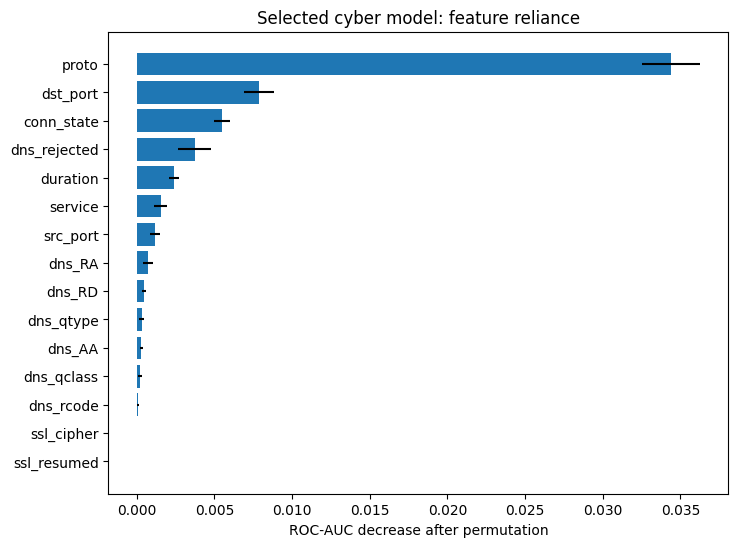

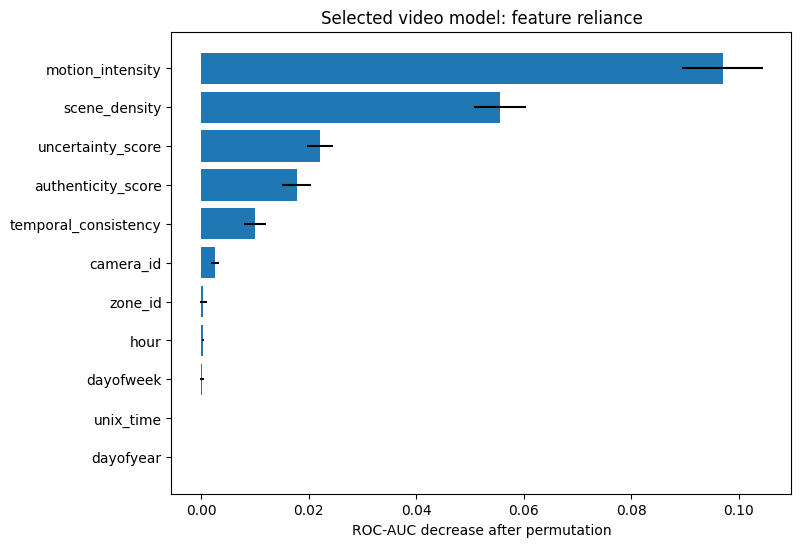

WindowsPath('F:/MBZUAI UAE/7-Elsevier-CHBR-Human-centered/GitHub-v2/Outputs/CHBR_R1_v3/tables/fusion_contribution_audit.json')

In [34]:
importance_rows, importance_ids = [], []
for branch in ("cyber", "video"):
    name = SELECTED[branch]
    key = (branch, "full", name)
    data, source, y, parts, columns = (Xc, cyber_df, yc, CPART, cyber_features) if branch == "cyber" else (
        video_df, video_df, yv, VPART, FEATURE_SETS["full"])
    evaluation = parts["test"]
    rng = np.random.default_rng(CONFIG["random_state"] + 704)
    indices = np.sort(rng.choice(evaluation, min(CONFIG["permutation_max_rows"], len(evaluation)), replace=False))
    importance_ids.append(pd.DataFrame({"branch": branch, "source_row_id": source.source_row_id.iloc[indices].to_numpy()}))
    if len(np.unique(y[indices])) < 2:
        status(f"inspection_{branch}", "not_estimable", "The label-blind inspection sample has a single class.")
        continue
    result = permutation_importance(FITTED[key], data.iloc[indices][columns], y[indices], scoring="roc_auc",
        n_repeats=CONFIG["permutation_repeats"], random_state=CONFIG["random_state"], n_jobs=1)
    for j, column in enumerate(columns):
        for rep, value in enumerate(result.importances[j]):
            importance_rows.append(dict(branch=branch, model=name, feature=column, rep=rep, importance=value))
importance = pd.DataFrame(importance_rows)
if len(importance):
    save_csv(importance, "permutation_importance_raw.csv")
    importance_summary = importance.groupby(["branch", "model", "feature"]).importance.agg(["mean", "std"]).reset_index()
    save_csv(importance_summary, "permutation_importance.csv")
    for branch in importance_summary.branch.unique():
        group = importance_summary[importance_summary.branch == branch].sort_values("mean").tail(15)
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.barh(group.feature, group["mean"], xerr=group["std"].fillna(0))
        ax.set(xlabel="ROC-AUC decrease after permutation", title=f"Selected {branch} model: feature reliance")
        save_fig(f"fig_{branch}_permutation_importance.png", fig)
save_csv(pd.concat(importance_ids, ignore_index=True), "inspection_record_ids.csv")
contributions = ftab[["window_id", "w_cyber", "w_video", "raw_fusion_score", "fusion_uncertainty", "adjusted_fusion_score"]].copy()
contributions["cyber_contribution"] = ftab.w_cyber * ftab.cyber_mean_prob.fillna(0)
contributions["video_contribution"] = ftab.w_video * ftab.video_mean_prob.fillna(0)
contributions["uncertainty_penalty"] = CONFIG["fusion_uncertainty_penalty"] * ftab.fusion_uncertainty
reconstructed = np.clip(contributions.cyber_contribution + contributions.video_contribution - contributions.uncertainty_penalty, 0, 1)
contributions["reconstruction_error"] = np.abs(reconstructed - ftab.adjusted_fusion_score)
assert contributions.reconstruction_error.max() < 1e-12
save_csv(contributions, "fusion_contribution_audit.csv.gz")
save_json({"max_reconstruction_error": contributions.reconstruction_error.max(),
           "meaning": "Algebraic score reconstruction, not explanation fidelity or human usability."}, "fusion_contribution_audit.json")

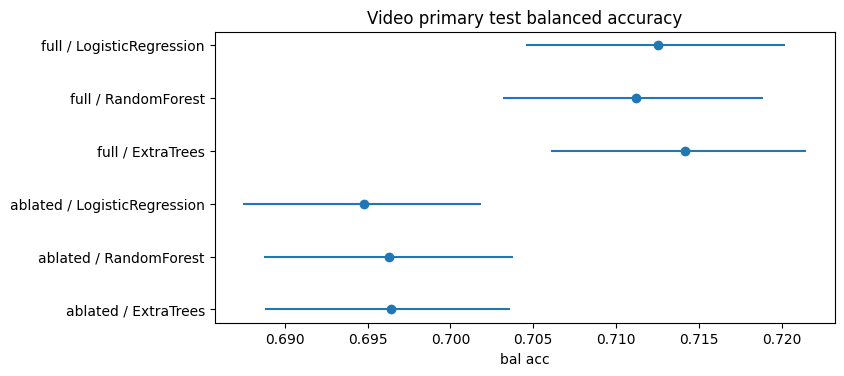

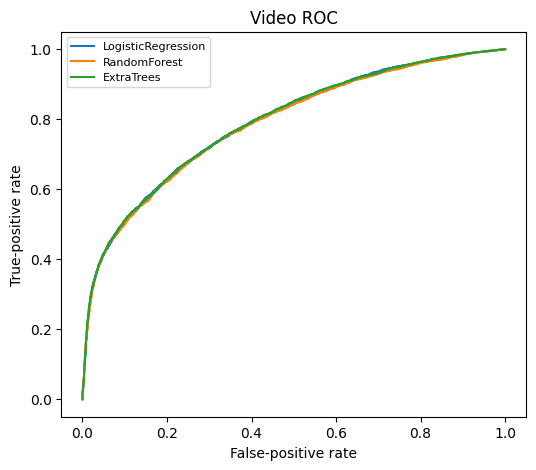

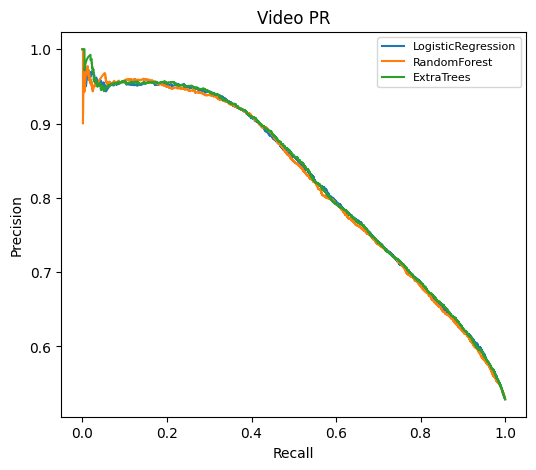

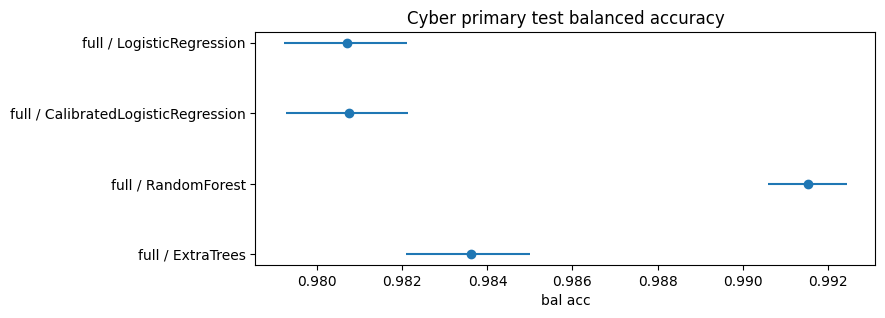

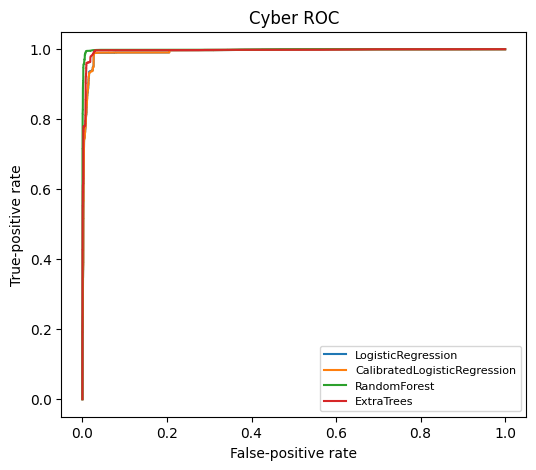

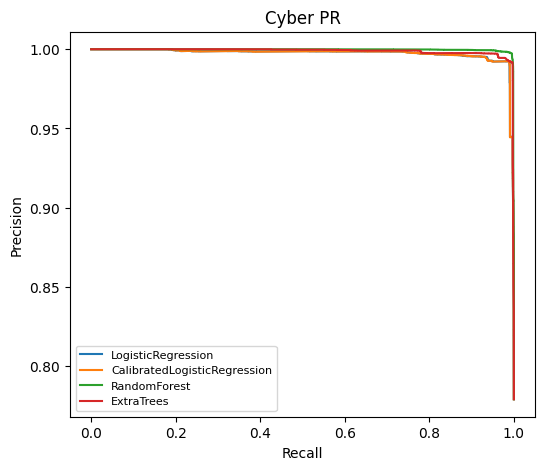

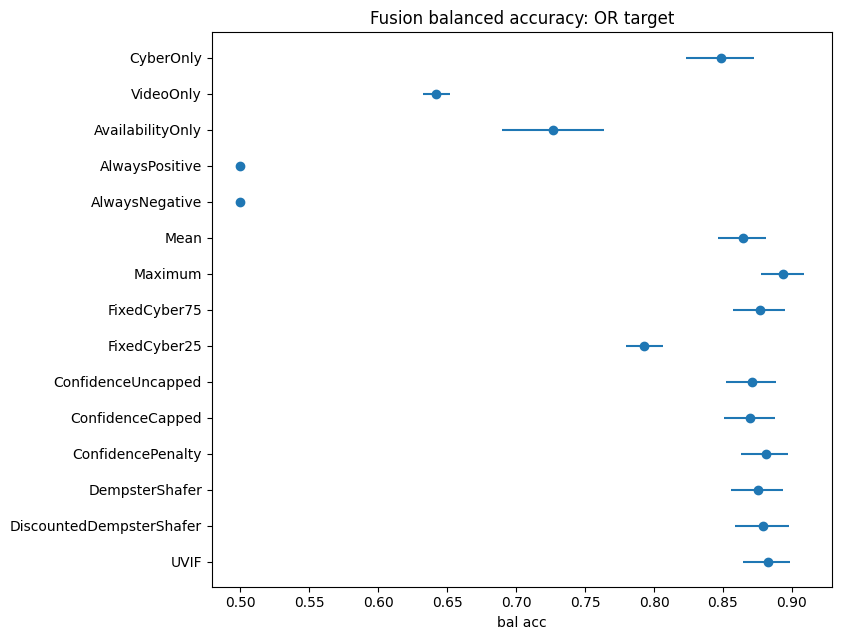

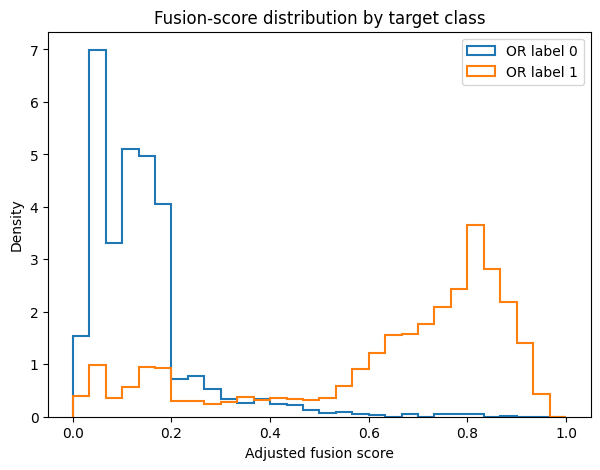

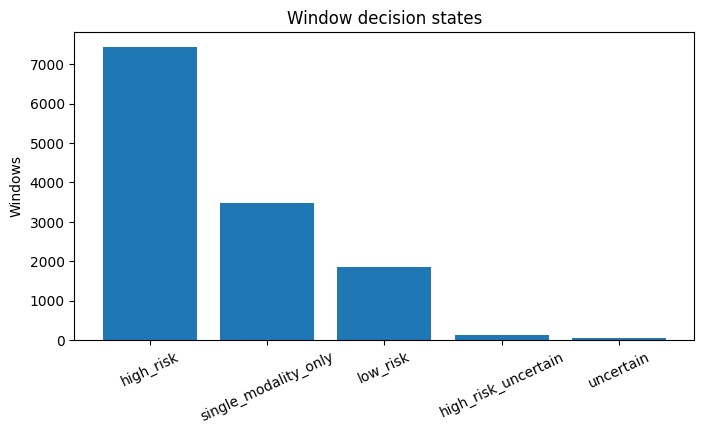

In [35]:
def plot_intervals(frame, metric, labels, title, filename):
    fig, ax = plt.subplots(figsize=(8, max(3, 0.38 * len(frame) + 1.5)))
    positions = np.arange(len(frame))
    ax.hlines(positions, frame[metric + "_lo"], frame[metric + "_hi"])
    ax.plot(frame[metric], positions, "o")
    ax.set_yticks(positions, labels)
    ax.set(xlabel=metric.replace("_", " "), title=title)
    ax.invert_yaxis()
    save_fig(filename, fig)


for branch in ("video", "cyber"):
    ci = BRANCH_CI[branch]
    plot_intervals(ci, "bal_acc", ci.feature_set + " / " + ci.model,
                   f"{branch.capitalize()} primary test balanced accuracy", f"fig_{branch}_model_comparison.png")
    for curve in ("roc", "pr"):
        fig, ax = plt.subplots(figsize=(6, 5))
        for key, prediction in PRIMARY_PREDICTIONS.items():
            if key[0] != branch or key[1] != "full" or prediction.label.nunique() < 2:
                continue
            if curve == "roc":
                x, z, _ = roc_curve(prediction.label, prediction.probability)
            else:
                z, x, _ = precision_recall_curve(prediction.label, prediction.probability)
            ax.plot(x, z, label=key[2])
        ax.set(xlabel="False-positive rate" if curve == "roc" else "Recall",
               ylabel="True-positive rate" if curve == "roc" else "Precision", title=f"{branch.capitalize()} {curve.upper()}")
        ax.legend(fontsize=8)
        save_fig(f"fig_{branch}_{curve}.png", fig)

main_fusion = fusion_results.query("target == 'target_or' and subset == 'all_observed'")
plot_intervals(main_fusion, "bal_acc", main_fusion.method, "Fusion balanced accuracy: OR target", "fig_fusion_baselines.png")
fig, ax = plt.subplots(figsize=(7, 5))
for label in (0, 1):
    ax.hist(ftab.loc[ftab.target_or == label, "adjusted_fusion_score"], bins=np.linspace(0, 1, 31),
            density=True, histtype="step", linewidth=1.5, label=f"OR label {label}")
ax.set(xlabel="Adjusted fusion score", ylabel="Density", title="Fusion-score distribution by target class")
ax.legend()
save_fig("fig_fusion_score_distribution.png", fig)

fig, ax = plt.subplots(figsize=(8, 4))
state_counts = ftab.window_state.value_counts()
ax.bar(state_counts.index, state_counts.values)
ax.tick_params(axis="x", rotation=25)
ax.set(ylabel="Windows", title="Window decision states")
save_fig("fig_fusion_window_states.png", fig)

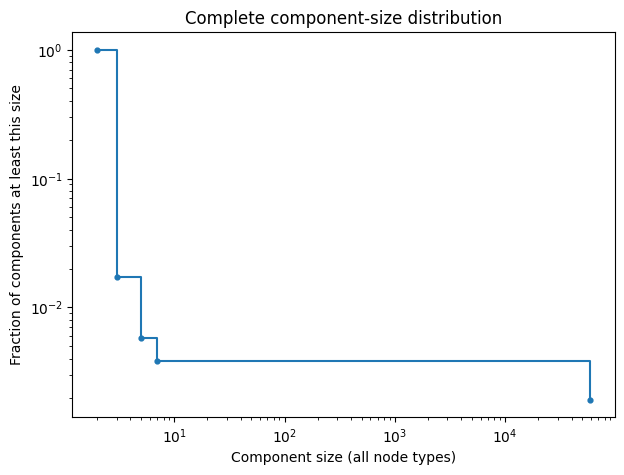

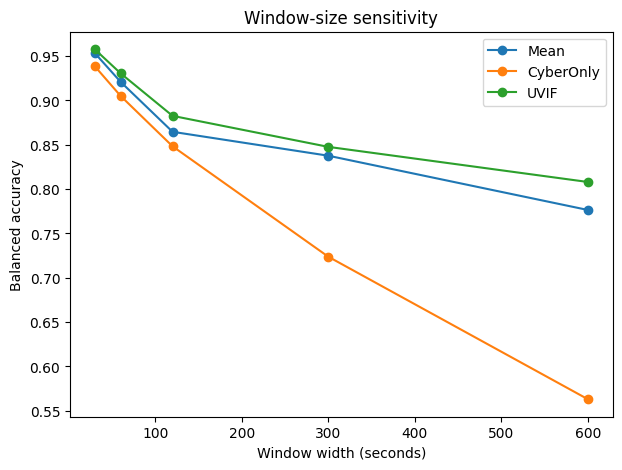

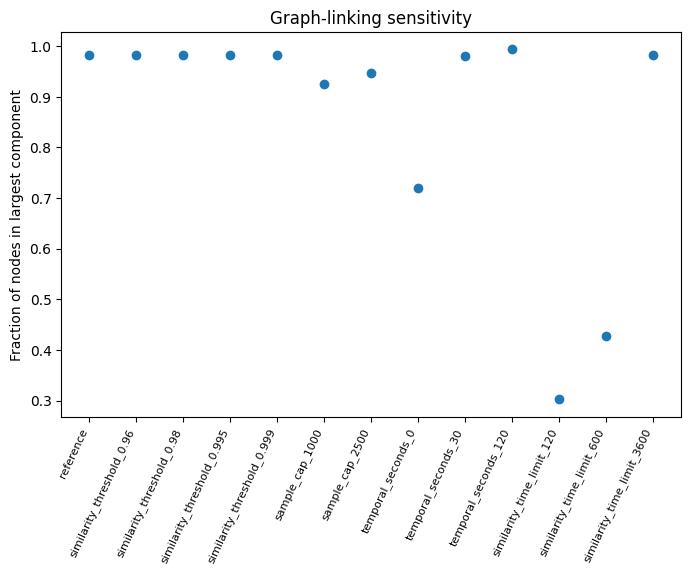

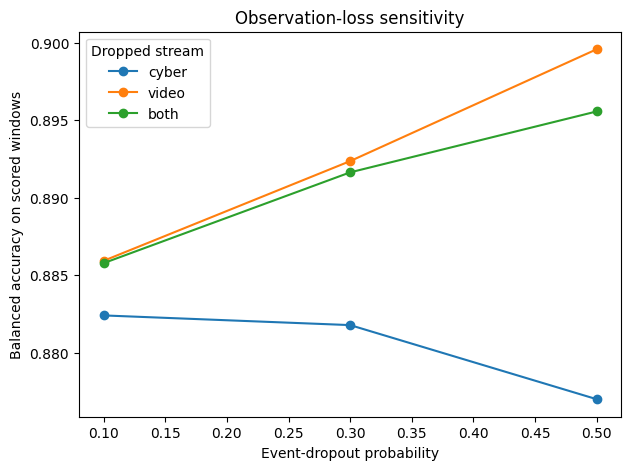

In [36]:
fig, ax = plt.subplots(figsize=(7, 5))
components = PRIMARY_GRAPH["components"]
if len(components):
    sizes = np.sort(components.nodes.to_numpy())
    unique, counts = np.unique(sizes, return_counts=True)
    ccdf = np.cumsum(counts[::-1])[::-1] / counts.sum()
    ax.step(unique, ccdf, where="post")
    ax.scatter(unique, ccdf, s=12)
    ax.set_xscale("log")
    ax.set_yscale("log")
ax.set(xlabel="Component size (all node types)", ylabel="Fraction of components at least this size",
       title="Complete component-size distribution")
save_fig("fig_campaign_size_distribution.png", fig)

fig, ax = plt.subplots(figsize=(7, 5))
for method in ("Mean", "CyberOnly", "UVIF"):
    data = window_sensitivity.query("method == @method and target == 'target_or'").sort_values("window_s")
    ax.plot(data.window_s, data.bal_acc, marker="o", label=method)
ax.set(xlabel="Window width (seconds)", ylabel="Balanced accuracy", title="Window-size sensitivity")
ax.legend()
save_fig("fig_window_sensitivity.png", fig)

fig, ax = plt.subplots(figsize=(8, 5))
graph_sensitivity = pd.DataFrame(graph_sensitivity_rows)
ax.plot(np.arange(len(graph_sensitivity)), graph_sensitivity.largest_frac, "o")
ax.set_xticks(np.arange(len(graph_sensitivity)), graph_sensitivity.scenario, rotation=65, ha="right", fontsize=8)
ax.set(ylabel="Fraction of nodes in largest component", title="Graph-linking sensitivity")
save_fig("fig_graph_sensitivity.png", fig)

fig, ax = plt.subplots(figsize=(7, 5))
for modality in ("cyber", "video", "both"):
    data = pd.DataFrame(stress_rows)
    data = data.query("stress == 'event_dropout' and target == 'target_or' and method == 'UVIF' and missing_modality == @modality").sort_values("missing_fraction")
    ax.plot(data.missing_fraction, data.bal_acc, marker="o", label=modality)
ax.set(xlabel="Event-dropout probability", ylabel="Balanced accuracy on scored windows", title="Observation-loss sensitivity")
ax.legend(title="Dropped stream")
save_fig("fig_missing_modality_sensitivity.png", fig)

## Validation and export

The checks below verify software invariants, not scientific acceptance. Complete interpretation still requires the generated results, the limits of the constructed targets, and the absence of synchronized campaign or human-evaluation ground truth.

In [37]:
def run_unit_checks():
    checks = []
    def check(name, condition):
        if not condition:
            raise AssertionError(name)
        checks.append({"check": name, "status": "passed"})
    y = np.array([0, 1, 0, 1, 1, 0])
    p = np.array([0.0, 0.5, 0.5, 0.9, 1.0, 1.0])
    metric = MetricEvaluator(y, p)()
    check("roc_auc_matches_sklearn_with_ties", np.isclose(metric["roc_auc"], roc_auc_score(y, p)))
    check("average_precision_matches_sklearn_with_ties", np.isclose(metric["pr_auc"], average_precision_score(y, p)))
    check("ece_includes_probability_one", np.isclose(MetricEvaluator([0], [1.0])()["ece"], 1.0))
    check("single_class_auc_is_missing", np.isnan(metrics([1, 1], [0.1, 0.9])["roc_auc"]))
    w = np.array([1, 2, 0, 3, 1, 1])
    weighted = MetricEvaluator(y, p)(w)
    check("weighted_auc_matches_sklearn", np.isclose(weighted["roc_auc"], roc_auc_score(y, p, sample_weight=w)))
    check("weighted_ap_matches_sklearn", np.isclose(weighted["pr_auc"], average_precision_score(y, p, sample_weight=w)))
    frame = pd.DataFrame(dict(cyber_mean_prob=[0.5, np.nan, 0.0, np.nan], video_mean_prob=[0.5, 0.8, 1.0, np.nan],
        cyber_mean_uncertainty=[1.0, np.nan, 0.0, np.nan], video_mean_uncertainty=[1.0, 0.4, 0.0, np.nan],
        cyber_count=[1, 0, 1, 0], video_count=[1, 1, 1, 0]))
    score, raw, uncertainty, weights = weighted_fusion(frame, 0.8, 0.3)
    check("zero_confidence_equal_weight_fallback", np.allclose(weights[0], [0.5, 0.5]))
    check("zero_confidence_preserves_ambiguity", raw[0] == 0.5 and uncertainty[0] == 1.0)
    check("missing_modality_zero_weight", np.allclose(weights[1], [0, 1]))
    check("no_observations_abstain", np.isnan(score[3]))
    check("dempster_shafer_conflict_finite", np.isclose(dempster_shafer(frame)[0][2], 0.5))
    draws = list(ResamplingPlan(11, "block", 4, seed=42).draws(200))
    check("bootstrap_keeps_sample_size", all(np.isclose(a.sum(), 11) for a in draws))
    check("bootstrap_can_sample_last_observation", any(a[-1] > 0 for a in draws))
    check("holm_bounds_and_monotonicity", np.allclose(holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06]))
    a = edge_matrix([1, 0, 0], [0, 1, 1], 3, 2)
    b = edge_matrix([0], [1], 3, 4)
    check("duplicate_edges_counted_once", (a + b).nnz == 1 and (a + b)[0, 1] == 6)
    check("isolated_graph_nodes_retained", connected_components(a, directed=False)[0] == 2)
    check("primary_partitions_disjoint", not np.intersect1d(VPART["train"], VPART["test"]).size)
    check("cyber_predictor_groups_disjoint", not np.intersect1d(cyber_groups[CPART["train"]], cyber_groups[CPART["test"]]).size)
    check("forbidden_features_absent", not set(FEATURE_SETS["full"]).intersection(FORBIDDEN_VIDEO))
    check("fusion_contributions_reconstruct_score", contributions.reconstruction_error.max() < 1e-12)
    check("window_reference_matches_main", all(np.isclose(
        reference_row.query("method == @m and target == 'target_or'").iloc[0].bal_acc,
        main_fusion.query("method == @m").iloc[0].bal_acc, equal_nan=True) for m in FUSION_METHODS))
    return pd.DataFrame(checks)


unit_checks = run_unit_checks()
save_csv(unit_checks, "validation_checks.csv")
status("software_checks", "complete", f"{len(unit_checks)} invariants passed.")

software_checks: complete. 21 invariants passed.


In [39]:
limitations = {
    "data": "Generated surveillance descriptors and an existing cyber subset; no independent physical-cyber test dataset.",
    "history": "The dataset has previously been inspected; within-run test separation is not a new prospective external validation.",
    "uncertainty": "Deterministic posterior-distance ambiguity, not epistemic uncertainty.",
    "alignment": "Synthetic cyber timing and label-blind paired diagnostics, not observed correspondence.",
    "fusion_target": "OR and AND of branch labels, not independent incident or campaign annotations.",
    "fusion_probability": "Adjusted scores and discounted masses are not asserted to be calibrated OR-event probabilities.",
    "baselines": "Dempster-Shafer algebra uses an explicitly defined score-to-mass mapping; no DDEF neural architecture is implemented.",
    "graph": "Same-modality score similarity and surrogate time do not prove campaign identity or causal linkage.",
    "statistics": "Conditional percentile intervals depend on cluster/block assumptions; repeated seeds and holdouts are descriptive sensitivity analyses.",
    "human_evaluation": "No human participants, cognitive-workload evaluation, trust evaluation, or feedback learning.",
}
save_json(limitations, "interpretation_limits.json")
flags = []
for availability, group in ftab.groupby("modality_count"):
    if group.target_or.nunique() < 2:
        flags.append(f"OR target has one class for modality_count={availability}; class-conditional fusion interpretation is limited.")
if PRIMARY_GRAPH["summary"]["largest_frac"] > 0.9:
    flags.append("More than 90% of graph nodes lie in the largest component; this is not evidence of campaign separation.")
if (ftab.cyber_count.eq(0) | ftab.video_count.eq(0)).any():
    flags.append("Modality-availability controls and stratified composition must accompany pooled fusion metrics.")
if (main_fusion.fpr == 0).any():
    flags.append("Some rules have zero observed false positives. A zero-width bootstrap interval does not establish zero population risk; IID binomial reference limits are supplied separately.")
flags.append(CONFIG["cyber_subset_provenance"])
for flag in flags:
    log("Interpretation note: " + flag)
save_json({"flags": flags, "limits": limitations}, "analysis_flags.json")
figure_index = pd.DataFrame({"file": sorted(path for path in ARTIFACTS if path.startswith("figures/") and path.endswith(".png"))})
save_csv(figure_index, "figure_index.csv")
status("pipeline", "complete", "All configured experiments and numerical exports completed.")
completion = {"status": "complete", "elapsed_seconds": time.perf_counter() - START_TIME,
              "unit_checks_passed": len(unit_checks), "cyber_sha256": cyber_audit["sha256"],
              "surveillance_sha256": sha256(video_file), "selected_models": SELECTED,
              "test_windows": len(ftab), "graph": PRIMARY_GRAPH["summary"], "interpretation_flags": flags}
save_json(completion, "run_summary.json")
log(f"Completed in {(time.perf_counter() - START_TIME) / 60:.1f} minutes. Outputs: {RUN_DIR}")
for handler in LOGGER.handlers:
    handler.flush()
register(RUN_DIR / "run_log.txt")
manifest_rows = []
for relative_path, description in sorted(ARTIFACTS.items()):
    path = RUN_DIR / relative_path
    manifest_rows.append({"file": relative_path, "bytes": path.stat().st_size, "sha256": sha256(path), "description": description})
manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(RUN_DIR / "manifest.csv", index=False)
bundle = RUN_DIR / "results_bundle.zip"
with zipfile.ZipFile(bundle, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(RUN_DIR.rglob("*")):
        if not path.is_file() or path == bundle:
            continue
        relative = path.relative_to(RUN_DIR)
        if "models" in relative.parts or "predictions" in relative.parts or path.suffix in (".npz", ".gz"):
            continue
        archive.write(path, relative.as_posix())
print(f"Result bundle: {bundle}")
display(unit_checks)
display(main_fusion[["method", "bal_acc", "roc_auc", "pr_auc", "f1", "fpr"]])

Interpretation note: More than 90% of graph nodes lie in the largest component; this is not evidence of campaign separation.
Interpretation note: Modality-availability controls and stratified composition must accompany pooled fusion metrics.
Interpretation note: Some rules have zero observed false positives. A zero-width bootstrap interval does not establish zero population risk; IID binomial reference limits are supplied separately.
Interpretation note: Parent-dataset subset selection not supplied; input file retained without resampling.
pipeline: complete. All configured experiments and numerical exports completed.
Completed in 35.0 minutes. Outputs: F:\MBZUAI UAE\7-Elsevier-CHBR-Human-centered\GitHub-v2\Outputs\CHBR_R1_v3
Result bundle: F:\MBZUAI UAE\7-Elsevier-CHBR-Human-centered\GitHub-v2\Outputs\CHBR_R1_v3\results_bundle.zip


,check,status
0,roc_auc_matches_sklearn_with_ties,passed
1,average_precision_matches_sklearn_with_ties,passed
2,ece_includes_probability_one,passed
3,single_class_auc_is_missing,passed
4,weighted_auc_matches_sklearn,passed
5,weighted_ap_matches_sklearn,passed
6,zero_confidence_equal_weight_fallback,passed
7,zero_confidence_preserves_ambiguity,passed
8,missing_modality_zero_weight,passed
9,no_observations_abstain,passed


,method,bal_acc,roc_auc,pr_auc,f1,fpr
0,CyberOnly,0.848260,0.845172,0.950288,0.821116,0.000000
1,VideoOnly,0.642369,0.695932,0.904228,0.582847,0.141452
2,AvailabilityOnly,0.727038,0.727038,0.879081,0.858673,0.369516
3,AlwaysPositive,0.500000,0.500000,0.796003,0.886416,1.000000
4,AlwaysNegative,0.500000,0.500000,0.796003,0.000000,0.000000
5,Mean,0.864600,0.908740,0.974093,0.875865,0.062405
6,Maximum,0.893786,0.939800,0.985347,0.900643,0.040091
7,FixedCyber75,0.876623,0.897282,0.974152,0.873665,0.027988
8,FixedCyber25,0.792849,0.870096,0.957778,0.879612,0.249622
9,ConfidenceUncapped,0.870774,0.903318,0.976271,0.874690,0.044629
